# Southend United vs Boreham Wood - chasing the leaders

Boreham Wood are top of the National League. This notebook puts Southend side by side with
them across every part of the game - results, attempts, territory, average positions, duels,
chance creation, pressing, strikers, goal timing, game state and passing style - to see where
the gap really is.

Both teams' league matches this season are loaded once at the top. Every chart after that
works from those events, so re-running the notebook later in the season updates everything.
Southend are always **blue**, Boreham Wood always **charcoal**.

A note on coordinates: Wyscout records every event from the point of view of the team that
made it, attacking towards x = 100. So "their" events are flipped where they share a pitch
with ours.

## Setup

Reload the `wyscout` package on every cell, load the API credentials and point at the local
Mongo cache.

In [35]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [36]:
import os
from collections import Counter, defaultdict

from dotenv import load_dotenv

load_dotenv()  # CLIENT_ID and CLIENT_SECRET for the Wyscout API, from notebooks/.env
os.environ.setdefault("MONGO_HOST", "localhost")  # every API response is cached in Mongo

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.transforms import offset_copy
from mplsoccer import Radar, add_image

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

## The two teams

Change `RIVAL` to compare Southend with any other club - every chart below follows it.

In [37]:
from wyscout.ids import BOREHAM_WOOD, SEASON_2026, SOUTHEND
from wyscout.data import filters
from wyscout.data.player import event_minute, minutes_played, player_spells
from wyscout.data.season import RESULT_POINTS, match_ppda, possession_by_match, season_events, season_label, season_results
from wyscout.match import get_match_details
from wyscout.team import get_team_details
from wyscout.viz.consts import APP_FONT, GRID, MUTED, RESULT_BG, RESULT_FG, TEXT
from wyscout.viz.pitch import make_pitch
from wyscout.viz.shots import plot_shots
from wyscout.viz.utils import load_image

SEASON = SEASON_2026
US, RIVAL = SOUTHEND, BOREHAM_WOOD
TEAMS = [US, RIVAL]

NAME = {t: get_team_details(t)["name"] for t in TEAMS}
BADGE = {t: load_image(get_team_details(t)["imageDataURL"]) for t in TEAMS}
COLOUR = {US: "#1f5fbf", RIVAL: "#2b2b2b"}
LIGHT = {US: "#a9c4ec", RIVAL: "#b5b5b5"}
CMAP = {US: "Blues", RIVAL: "Greys"}
LABEL = season_label(SEASON)

print(f"{NAME[US]} vs {NAME[RIVAL]}, National League {LABEL}")

Southend United vs Boreham Wood, National League 2026/27


## Load both seasons

One entry per league match with its summary and both sides' events. This is the only cell
that touches the API (or the cache).

In [38]:
GAMES = {t: season_events(t, SEASON) for t in TEAMS}
RESULTS = {t: season_results(t, SEASON) for t in TEAMS}

for t in TEAMS:
    r = RESULTS[t]
    print(f"{NAME[t]:<18} played {len(r):>2}, events for {len(GAMES[t]):>2}, "
          f"points {r.points.iloc[-1]}, goals {r.cum_gf.iloc[-1]}-{r.cum_ga.iloc[-1]}")

Southend United    played 11, events for 11, points 21, goals 26-17
Boreham Wood       played 11, events for 11, points 29, goals 29-12


## Helpers

Small pieces used by the charts below: our events and theirs in a match, flipping
coordinates, a two-pitch figure with a header and both badges, and per-90 rates.

In [39]:
def ours(m, t):
    return filters.for_team(m["events"], t)


def theirs(m, t):
    return filters.against_team(m["events"], t)


def season_ours(t):
    return [e for m in GAMES[t] for e in ours(m, t)]


def season_theirs(t):
    return [e for m in GAMES[t] for e in theirs(m, t)]


def xy(events):
    """(xs, ys) arrays of the events' locations."""
    pts = np.array(filters.locations(events), dtype=float).reshape(-1, 2)
    return pts[:, 0], pts[:, 1]


def pct(a, b):
    return 100 * a / b if b else np.nan


BIG_CHANCE_XG = 0.3  # Wyscout's "opportunity" tag is on most attempts, so a big chance is judged on xG


def is_big_chance(shot):
    return shot["shot"]["xg"] >= BIG_CHANCE_XG


def contested_duels(events, kind=None):
    """Aerial and ground duels - loose-ball duels are left out, Wyscout records no winner for them."""
    return [d for d in filters.duels(events, kind) if "loose_ball_duel" not in filters.secondary(d)]


def font(size):
    """The house font at a given size - passing fontproperties would otherwise reset fontsize."""
    prop = APP_FONT.prop.copy()
    prop.set_size(size)
    return prop


def surname(name):
    return name.split(". ", 1)[-1]


def two_pitches(title, subtitle="", half=False, fig_height=9, panel_titles=None, **pitch_kwargs):
    """A pitch per team, Southend left, with a title, subtitle and both badges.

    Returns (fig, {team_id: ax}, pitch).
    """
    pitch = make_pitch(half=half, linewidth=1.5, pad_top=4, pad_bottom=-10 if half else 2, **pitch_kwargs)
    fig, axs = pitch.grid(ncols=2, figheight=fig_height, title_height=0.09, title_space=0.07,
                          endnote_height=0.01, grid_height=0.78, axis=False, grid_width=0.9, left=0.05)
    title_ax = axs["title"]
    title_ax.text(0, 0.75, title, fontsize=fig_height * 3, color=TEXT, fontproperties=APP_FONT.prop, va="center")
    if subtitle:
        title_ax.text(0, 0.15, subtitle, fontsize=fig_height * 1.7, color=MUTED, fontproperties=APP_FONT.prop,
                      va="center")
    pos = title_ax.get_position()
    for i, t in enumerate(reversed(TEAMS)):
        add_image(BADGE[t], fig, left=pos.x1 - 0.06 - i * 0.07, bottom=pos.y0, height=pos.height * 0.95,
                  interpolation="hanning")
    axes = dict(zip(TEAMS, axs["pitch"]))
    for t, ax in axes.items():
        ax.set_title((panel_titles or {}).get(t, NAME[t]), color=COLOUR[t], fontproperties=font(fig_height * 1.9), pad=6)
    return fig, axes, pitch


def chart_title(fig, title, subtitle=""):
    """Title and subtitle in the house style above a plain matplotlib figure."""
    fig.tight_layout()
    fig.text(0.01, 1, title, ha="left", va="bottom", fontsize=22, color=TEXT, fontproperties=APP_FONT.prop,
             transform=offset_copy(fig.transFigure, fig=fig, y=24, units="points"))
    if subtitle:
        fig.text(0.01, 1, subtitle, ha="left", va="bottom", fontsize=13, color=MUTED, fontproperties=APP_FONT.prop,
                 transform=offset_copy(fig.transFigure, fig=fig, y=6, units="points"))


def team_legend(ax, **kwargs):
    ax.legend(handles=[Patch(color=COLOUR[t], label=NAME[t]) for t in TEAMS], frameon=False, **kwargs)


def tidy(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color=GRID)
    ax.set_axisbelow(True)

## Per-match numbers

One row per team per match with everything the charts compare. Some definitions:

- **xG / xGA** - expected goals for and against, penalties and direct free kicks included.
- **PPDA** - passes the opposition were allowed in their build-up for each defensive action
  we made there. Lower means a more intense press. This is Wyscout's own figure from the
  advanced match stats (`wyscout.data.season.match_ppda`), so it agrees with `season.ipynb`
  and the Wyscout platform. It is blank for a match whose advanced stats are not published yet.
- **Field tilt** - our share of all touches in either final third. 50% is even; above 50%
  means the game was played in their half.
- **Big chances** - attempts worth 0.3 xG or more.
- **Duels won** - aerial and ground duels; loose-ball duels have no recorded winner.
- **High recoveries** - balls won back in the opposition half.

In [40]:
def match_metrics(m, t):
    s = m["summary"]
    us, them = ours(m, t), theirs(m, t)
    shots = filters.attempts(us, include_pens=True, include_free_kicks=True)
    shots_against = filters.attempts(them, include_pens=True, include_free_kicks=True)
    passes = filters.passes(us)
    duels = contested_duels(us)
    aerials = contested_duels(us, "aerial")

    ppda = match_ppda(s.match_id)
    final_third_us = sum(1 for e in us if filters.in_final_third(e))
    final_third_them = sum(1 for e in them if filters.in_final_third(e))
    recoveries = [e for e in us if "recovery" in filters.secondary(e) and filters.has_location(e)]
    tagged = lambda events, tag: sum(1 for e in events if tag in filters.secondary(e))

    return {
        "team_id": t,
        "team": NAME[t],
        "match_id": s.match_id,
        "date": s.date,
        "opponent": s.opponent,
        "venue": s.venue,
        "result": s.result,
        "points": RESULT_POINTS[s.result],
        "goals": s.goals_for,
        "conceded": s.goals_against,
        "xG": sum(e["shot"]["xg"] for e in shots),
        "xGA": sum(e["shot"]["xg"] for e in shots_against),
        "shots": len(shots),
        "shots_against": len(shots_against),
        "on_target": sum(1 for e in shots if e["shot"]["onTarget"]),
        "big_chances": sum(1 for e in shots if is_big_chance(e)),
        "big_chances_against": sum(1 for e in shots_against if is_big_chance(e)),
        "passes": len(passes),
        "pass_accuracy": pct(sum(1 for p in passes if p["pass"]["accurate"]), len(passes)),
        "progressive_passes": tagged(passes, "progressive_pass"),
        "passes_into_box": tagged(passes, "pass_to_penalty_area"),
        "key_passes": tagged(us, "key_pass"),
        "crosses": len(filters.crosses(us)),
        "box_touches": tagged(us, "touch_in_box"),
        "box_touches_against": tagged(them, "touch_in_box"),
        "duels_won": pct(sum(1 for d in duels if filters.duel_won(d)), len(duels)),
        "aerials_won": pct(sum(1 for d in aerials if filters.duel_won(d)), len(aerials)),
        "ppda": ppda[t] if ppda else np.nan,
        "field_tilt": pct(final_third_us, final_third_us + final_third_them),
        "recoveries": len(recoveries),
        "high_recoveries": sum(1 for e in recoveries if e["location"]["x"] >= 50),
        "counterpress_recoveries": tagged(us, "counterpressing_recovery"),
        "fouls": len(filters.fouls(us)),
    }


per_match = pd.DataFrame([match_metrics(m, t) for t in TEAMS for m in GAMES[t]])
per_match["game"] = per_match.groupby("team_id").cumcount() + 1
possession = pd.concat([possession_by_match(t, SEASON).assign(team_id=t) for t in TEAMS])
per_match = per_match.merge(possession[["team_id", "match_id", "possession"]], on=["team_id", "match_id"], how="left")

per_game = per_match.groupby("team").mean(numeric_only=True).drop(columns=["team_id", "match_id", "game"]).T
per_game = per_game[[NAME[t] for t in TEAMS]].round(2)
per_game

team,Southend United,Boreham Wood
points,1.91,2.64
goals,2.36,2.64
conceded,1.55,1.09
xG,2.13,2.41
xGA,1.70,1.05
shots,15.18,14.64
shots_against,10.36,8.27
on_target,6.45,5.91
big_chances,1.73,2.27
big_chances_against,1.45,0.91


---
# 1. The title race

Points accumulated game by game, with the gap shaded, and each team's run of results
underneath. The gap at the end of the line is what Southend need to close.

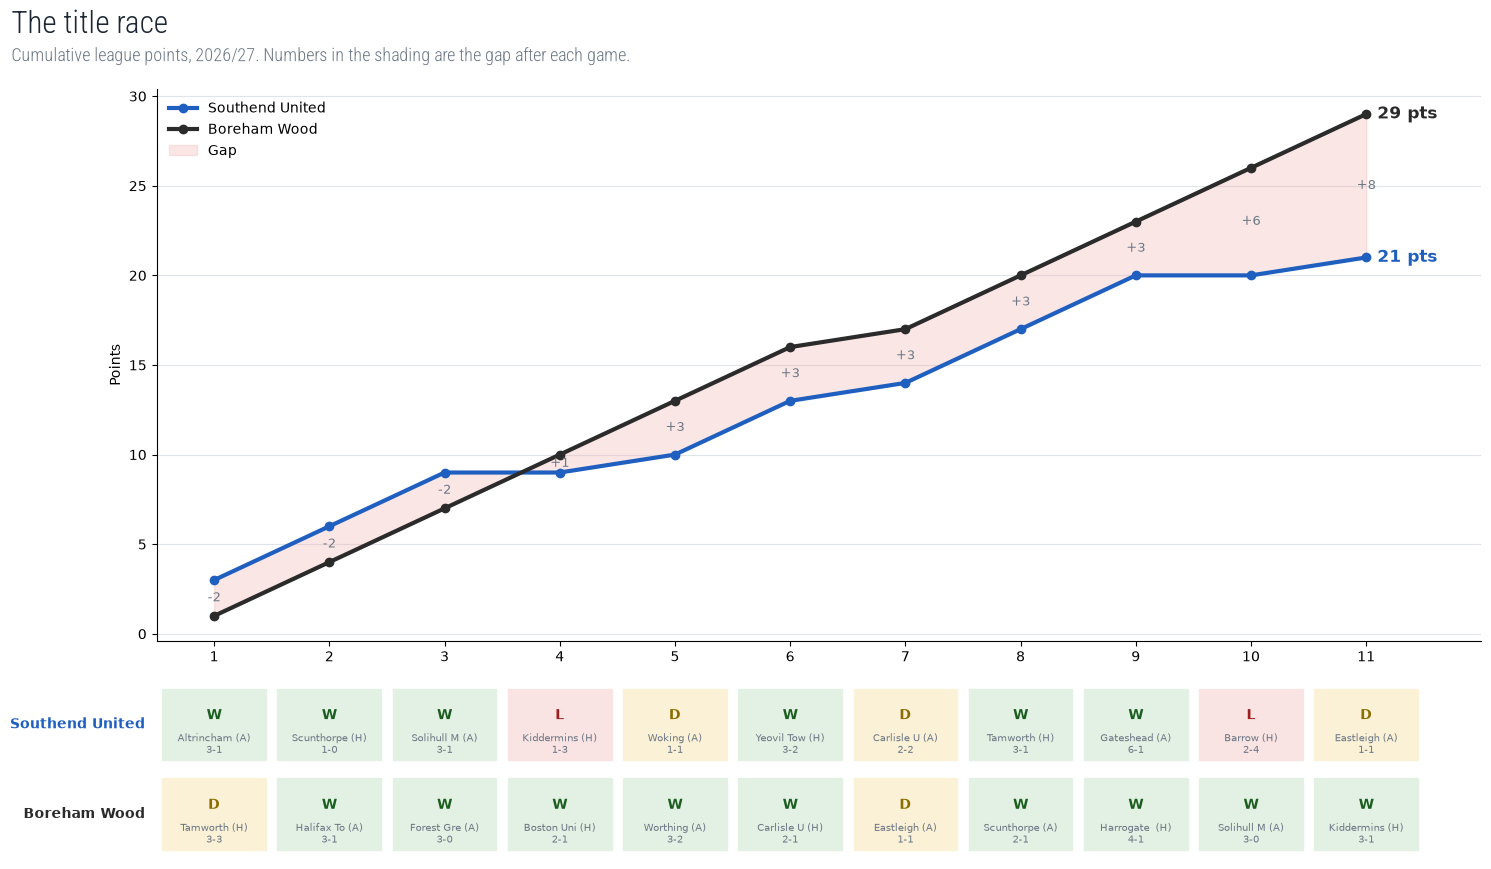

In [41]:
fig, (ax, strip) = plt.subplots(2, 1, figsize=(15, 8), gridspec_kw={"height_ratios": [4, 1.3]})
games = max(len(RESULTS[t]) for t in TEAMS)
for t in TEAMS:
    r = RESULTS[t]
    ax.plot(r.game, r.points, marker="o", lw=3, color=COLOUR[t], label=NAME[t])
    ax.annotate(f"{r.points.iloc[-1]} pts", (r.game.iloc[-1], r.points.iloc[-1]), xytext=(8, 0),
                textcoords="offset points", va="center", color=COLOUR[t], weight="bold", fontsize=12)
both = RESULTS[US][["game", "points"]].merge(RESULTS[RIVAL][["game", "points"]], on="game", suffixes=("_us", "_them"))
ax.fill_between(both.game, both.points_us, both.points_them, color="#f2b8b5", alpha=0.35, label="Gap")
for _, row in both.iterrows():
    gap = row.points_them - row.points_us
    ax.text(row.game, (row.points_us + row.points_them) / 2, f"{gap:+d}", ha="center", va="center", fontsize=9, color=MUTED)
ax.set_xlim(0.5, games + 1)
ax.set_ylabel("Points")
ax.set_xticks(range(1, games + 1))
ax.legend(frameon=False, loc="upper left")
tidy(ax)

strip.set_xlim(0.5, games + 1)
strip.set_ylim(-0.5, 1.5)
strip.axis("off")
for row, t in enumerate(TEAMS):
    for _, g in RESULTS[t].iterrows():
        strip.add_patch(plt.Rectangle((g.game - 0.45, 1 - row - 0.4), 0.9, 0.8, color=RESULT_BG[g.result]))
        strip.text(g.game, 1 - row + 0.1, g.result, ha="center", va="center", weight="bold", color=RESULT_FG[g.result])
        strip.text(g.game, 1 - row - 0.22, f"{g.opponent[:10]} ({g.venue})\n{g.gf}-{g.ga}", ha="center",
                   va="center", fontsize=7, color=MUTED)
    strip.text(0.4, 1 - row, NAME[t], ha="right", va="center", color=COLOUR[t], weight="bold")

chart_title(fig, "The title race", f"Cumulative league points, {LABEL}. Numbers in the shading are the gap after each game.")
plt.show()

---
# 2. Tale of the tape

Per-game averages for the season, side by side. Each row is scaled to the larger of the two
values, and the team that does better in that row is in full colour - for the "against"
rows and PPDA, lower is better.

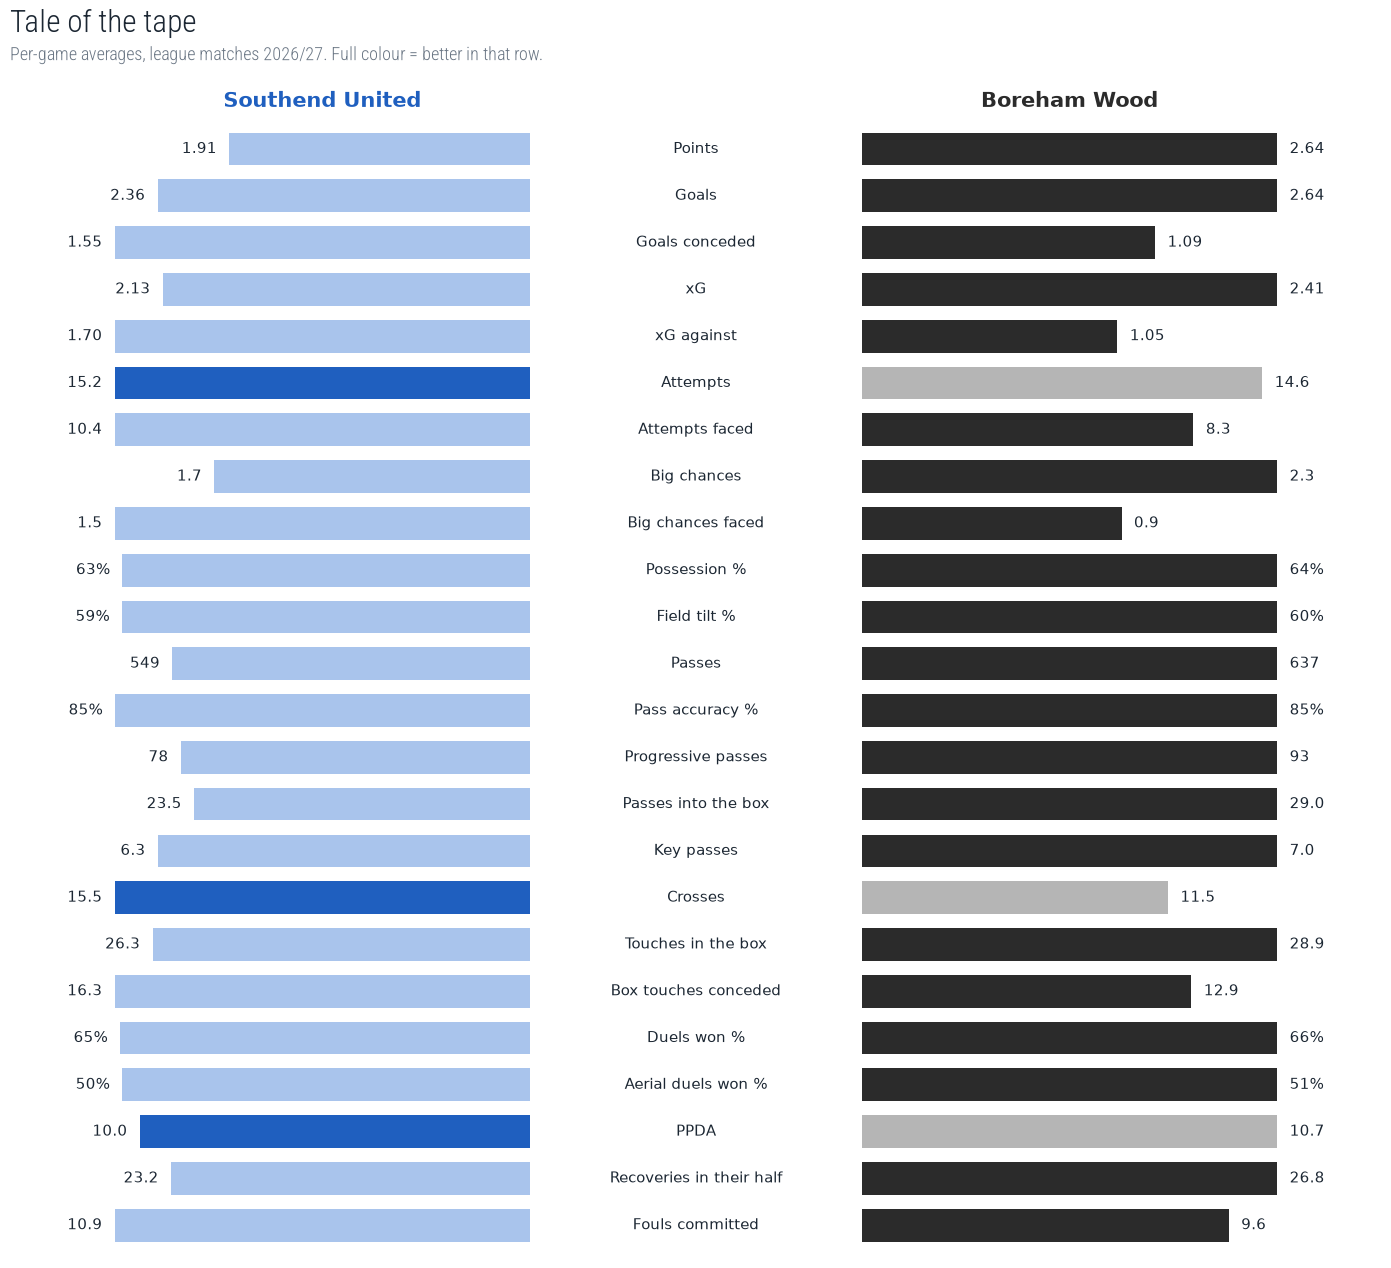

In [42]:
TAPE = [  # column, label, higher is better, format
    ("points", "Points", True, "{:.2f}"),
    ("goals", "Goals", True, "{:.2f}"),
    ("conceded", "Goals conceded", False, "{:.2f}"),
    ("xG", "xG", True, "{:.2f}"),
    ("xGA", "xG against", False, "{:.2f}"),
    ("shots", "Attempts", True, "{:.1f}"),
    ("shots_against", "Attempts faced", False, "{:.1f}"),
    ("big_chances", "Big chances", True, "{:.1f}"),
    ("big_chances_against", "Big chances faced", False, "{:.1f}"),
    ("possession", "Possession %", True, "{:.0f}%"),
    ("field_tilt", "Field tilt %", True, "{:.0f}%"),
    ("passes", "Passes", True, "{:.0f}"),
    ("pass_accuracy", "Pass accuracy %", True, "{:.0f}%"),
    ("progressive_passes", "Progressive passes", True, "{:.0f}"),
    ("passes_into_box", "Passes into the box", True, "{:.1f}"),
    ("key_passes", "Key passes", True, "{:.1f}"),
    ("crosses", "Crosses", True, "{:.1f}"),
    ("box_touches", "Touches in the box", True, "{:.1f}"),
    ("box_touches_against", "Box touches conceded", False, "{:.1f}"),
    ("duels_won", "Duels won %", True, "{:.0f}%"),
    ("aerials_won", "Aerial duels won %", True, "{:.0f}%"),
    ("ppda", "PPDA", False, "{:.1f}"),
    ("high_recoveries", "Recoveries in their half", True, "{:.1f}"),
    ("fouls", "Fouls committed", False, "{:.1f}"),
]

means = per_match.groupby("team_id").mean(numeric_only=True)
MID = 0.4  # half the width of the centre column that holds the labels
fig, ax = plt.subplots(figsize=(14, 12))
for i, (col, label, higher_better, fmt) in enumerate(TAPE):
    us, them = means.loc[US, col], means.loc[RIVAL, col]
    top = max(us, them) or 1
    best_us = (us >= them) if higher_better else (us <= them)
    y = len(TAPE) - i
    ax.barh(y, -us / top, left=-MID, color=COLOUR[US] if best_us else LIGHT[US], height=0.7)
    ax.barh(y, them / top, left=MID, color=COLOUR[RIVAL] if not best_us else LIGHT[RIVAL], height=0.7)
    ax.text(-MID - us / top - 0.03, y, fmt.format(us), ha="right", va="center", fontsize=11, color=TEXT)
    ax.text(MID + them / top + 0.03, y, fmt.format(them), ha="left", va="center", fontsize=11, color=TEXT)
    ax.text(0, y, label, ha="center", va="center", fontsize=11, color=TEXT)
ax.set_xlim(-MID - 1.25, MID + 1.25)
ax.set_ylim(0.3, len(TAPE) + 1.2)
ax.axis("off")
ax.text(-MID - 0.5, len(TAPE) + 0.9, NAME[US], ha="center", fontsize=15, weight="bold", color=COLOUR[US])
ax.text(MID + 0.5, len(TAPE) + 0.9, NAME[RIVAL], ha="center", fontsize=15, weight="bold", color=COLOUR[RIVAL])
chart_title(fig, "Tale of the tape", f"Per-game averages, league matches {LABEL}. Full colour = better in that row.")
plt.show()

## Style radar

The same numbers as a shape. Each spoke runs from the worst to the best single-match value
either team has produced this season, so a bigger shape is better everywhere (the scales for
the "against" stats and PPDA are reversed).

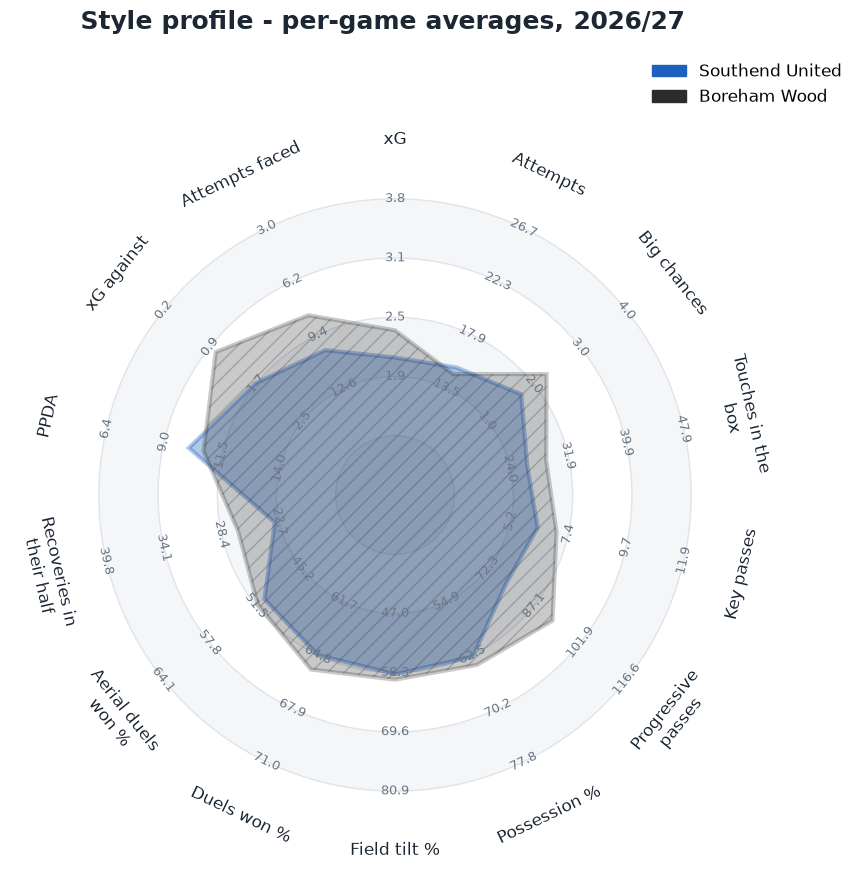

In [43]:
RADAR = [("xG", False), ("shots", False), ("big_chances", False), ("box_touches", False),
         ("key_passes", False), ("progressive_passes", False), ("possession", False), ("field_tilt", False),
         ("duels_won", False), ("aerials_won", False), ("high_recoveries", False), ("ppda", True),
         ("xGA", True), ("shots_against", True)]
labels = {c: l for c, l, *_ in TAPE}
params = [labels[c] for c, _ in RADAR]
low = [per_match[c].quantile(0.05) for c, _ in RADAR]
high = [per_match[c].quantile(0.95) for c, _ in RADAR]
radar = Radar(params, low, high, lower_is_better=[labels[c] for c, lower in RADAR if lower],
              round_int=[False] * len(RADAR), num_rings=4, ring_width=1, center_circle_radius=1)

fig, ax = radar.setup_axis(figsize=(10, 10))
radar.draw_circles(ax=ax, facecolor="#f4f6f8", edgecolor=GRID)
radar.draw_radar_compare(
    [means.loc[US, c] for c, _ in RADAR], [means.loc[RIVAL, c] for c, _ in RADAR], ax=ax,
    kwargs_radar={"facecolor": COLOUR[US], "alpha": 0.35, "edgecolor": COLOUR[US], "linewidth": 3},
    kwargs_compare={"facecolor": COLOUR[RIVAL], "alpha": 0.25, "edgecolor": COLOUR[RIVAL], "linewidth": 3,
                    "hatch": "//"},
)
radar.draw_range_labels(ax=ax, fontsize=9, color=MUTED)
radar.draw_param_labels(ax=ax, fontsize=12, color=TEXT)
team_legend(ax, loc="upper right", bbox_to_anchor=(1.1, 1.08), fontsize=12)
fig.suptitle(f"Style profile - per-game averages, {LABEL}", fontsize=18, weight="bold", color=TEXT, y=0.98)
plt.show()

---
# 3. Goal attempts

## Where the attempts come from

Every attempt this season, penalties and direct free kicks included. Marker area is xG, a
red ring is a goal, the darker shade is on target.

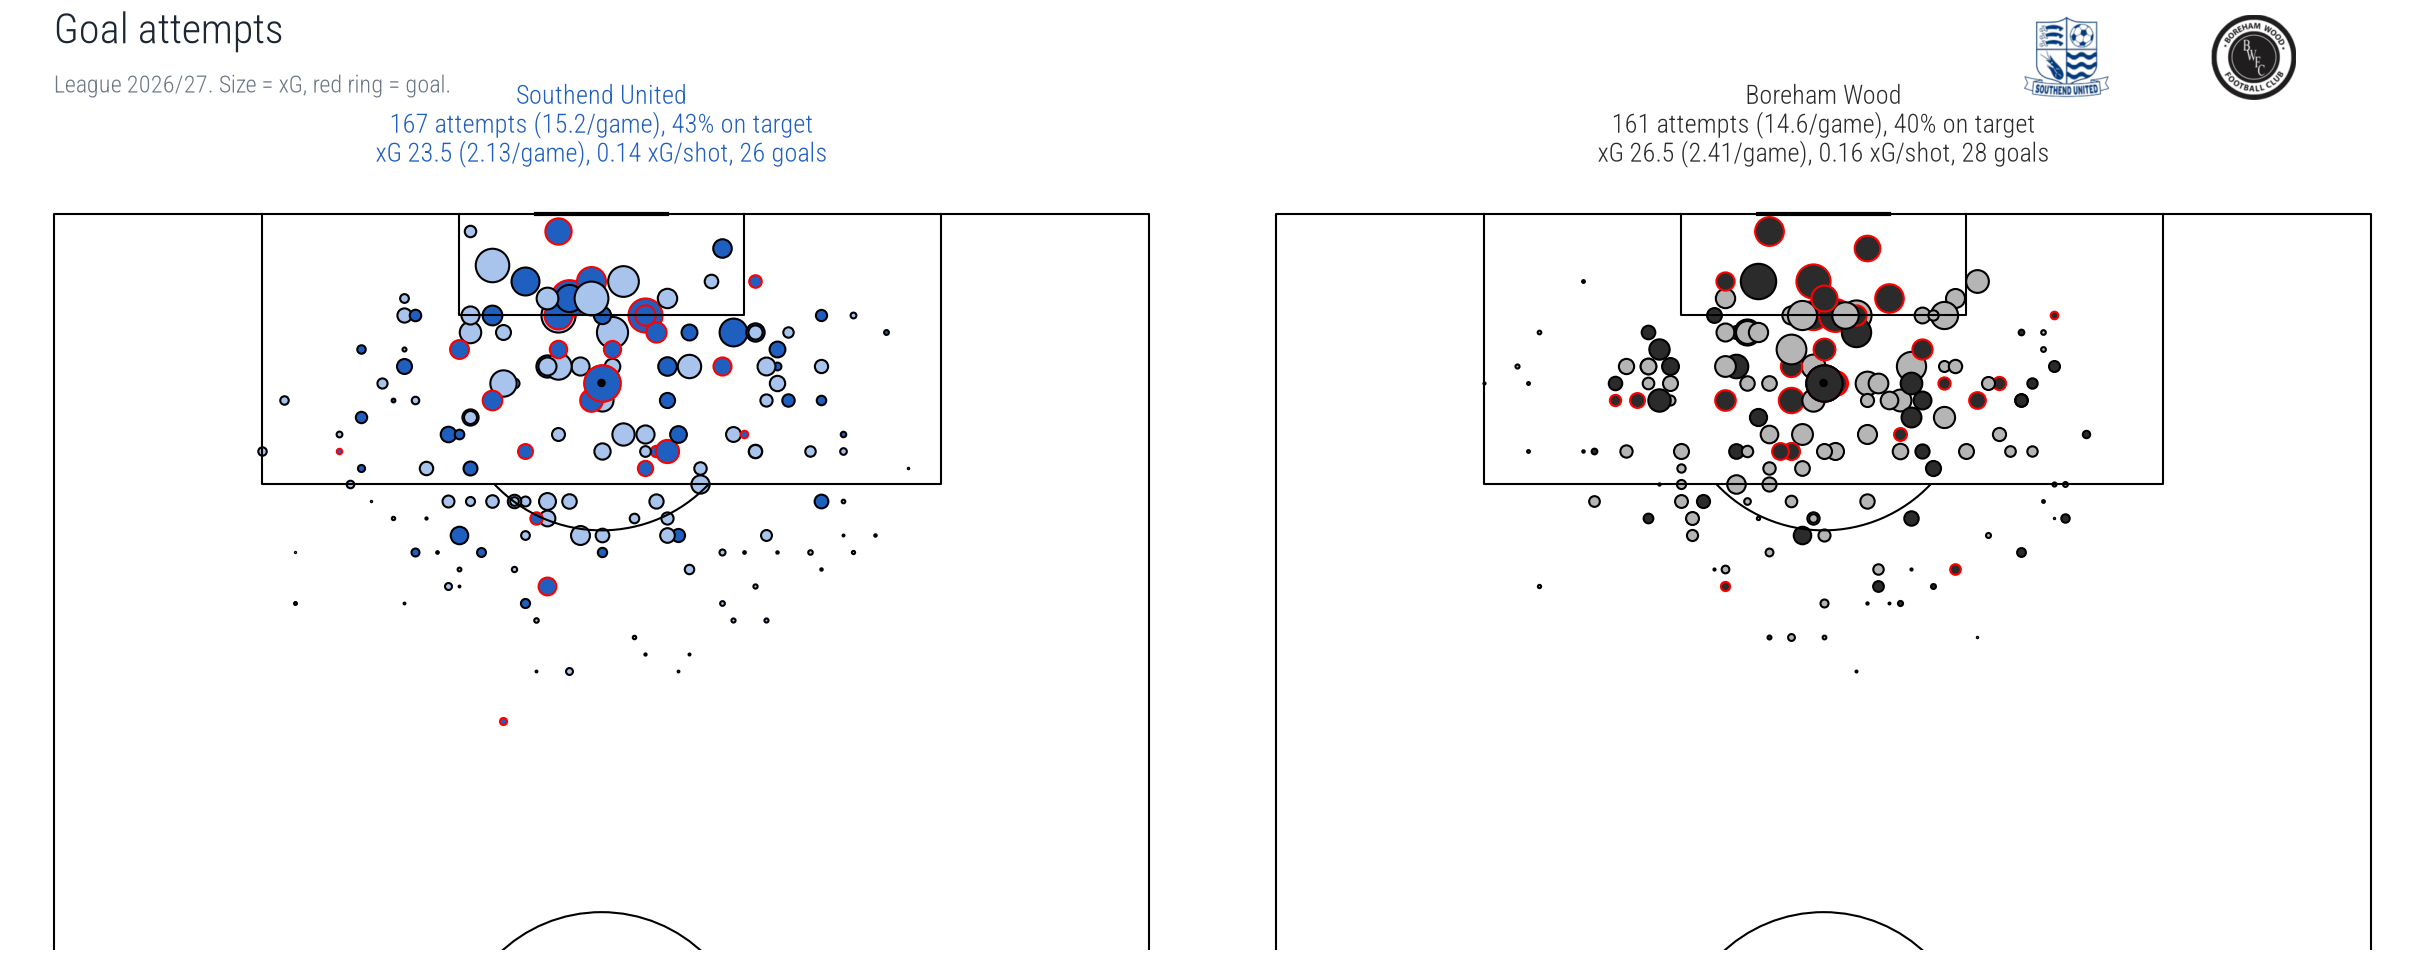

In [44]:
def attempt_summary(shots, games):
    s = len(shots)
    xg = sum(e["shot"]["xg"] for e in shots)
    goals = sum(1 for e in shots if e["shot"]["isGoal"])
    on_target = sum(1 for e in shots if e["shot"]["onTarget"])
    return (f"{s} attempts ({s / games:.1f}/game), {pct(on_target, s):.0f}% on target\n"
            f"xG {xg:.1f} ({xg / games:.2f}/game), {xg / s if s else 0:.2f} xG/shot, {goals} goals")


def attempts_figure(against=False):
    shots = {t: filters.attempts(season_theirs(t) if against else season_ours(t), include_pens=True,
                                 include_free_kicks=True) for t in TEAMS}
    titles = {t: f"{NAME[t]}\n{attempt_summary(shots[t], len(GAMES[t]))}" for t in TEAMS}
    fig, axes, pitch = two_pitches(
        "Attempts faced" if against else "Goal attempts",
        f"League {LABEL}. " + ("Where the opposition shot from against each team. " if against else "")
        + "Size = xG, red ring = goal.",
        half=True, fig_height=10, panel_titles=titles,
    )
    for t, ax in axes.items():
        colours = ("#c62828", "#ef9a9a") if against else (COLOUR[t], LIGHT[t])
        plot_shots(shots[t], colours, pitch, ax, base_size=900, line_width=1.5)
    plt.show()


attempts_figure()

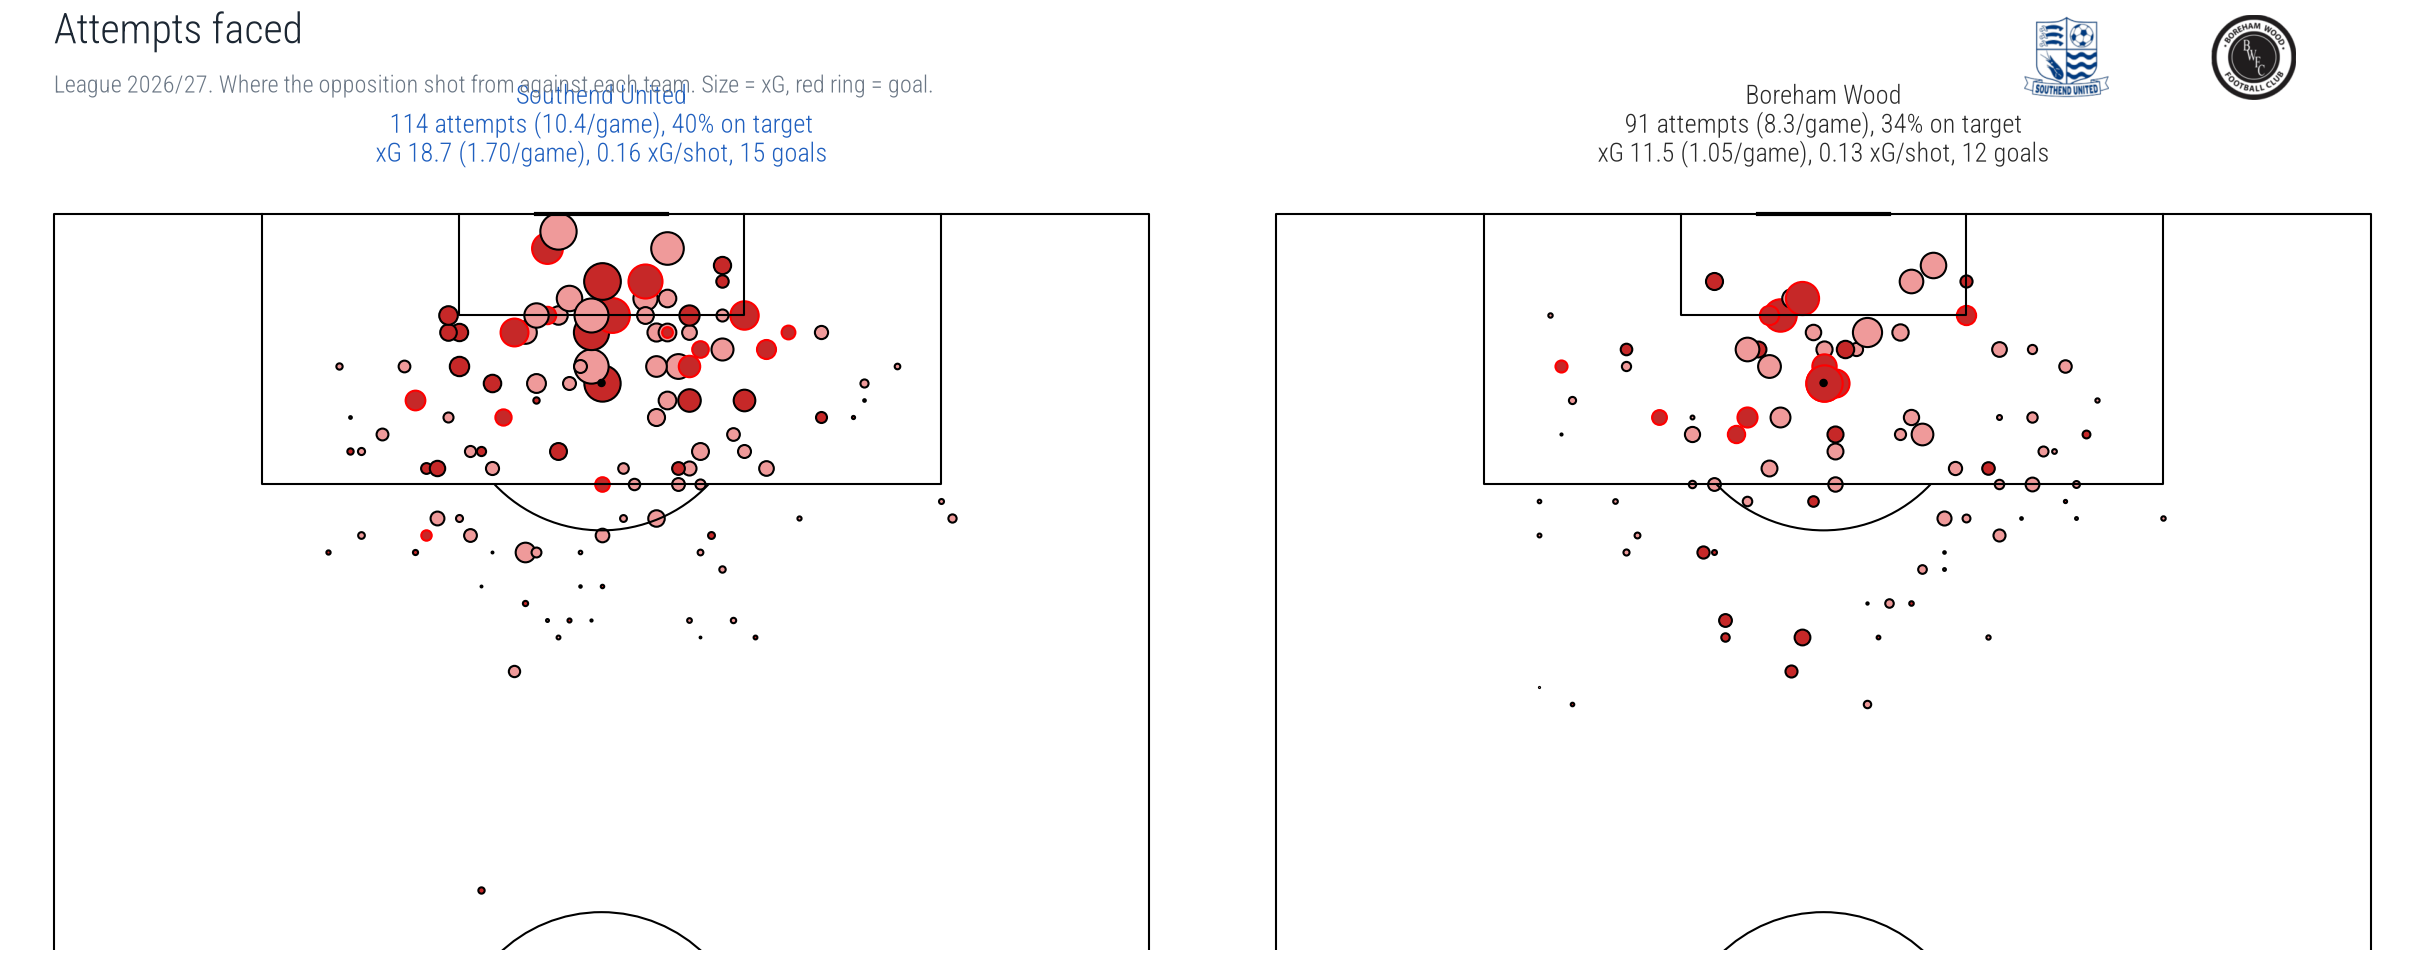

In [45]:
attempts_figure(against=True)

## Shot quality

Left: how far out the attempts are taken - a team that works the ball into the box shoots
from closer in. Right: the xG of each attempt. A long tail to the right means a team creates
genuine chances rather than speculative efforts.

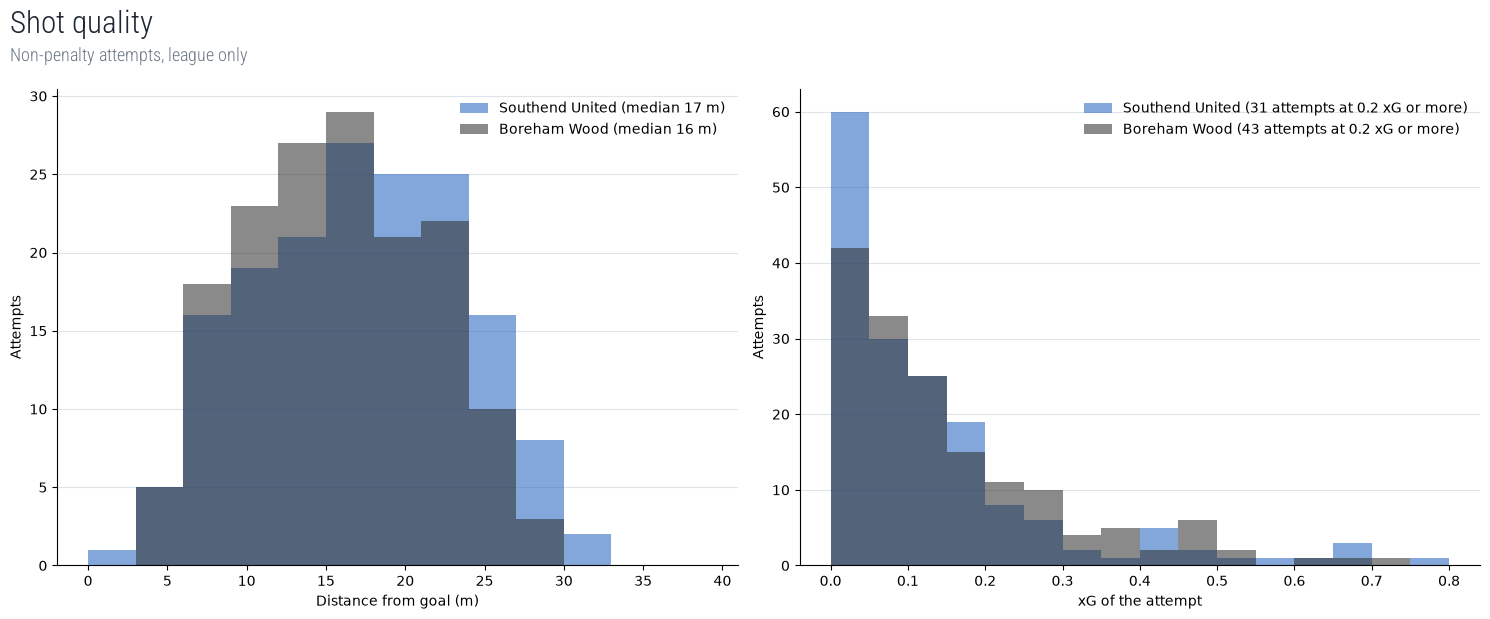

In [46]:
fig, (left, right) = plt.subplots(1, 2, figsize=(15, 5.5))
for t in TEAMS:
    shots = filters.attempts(season_ours(t), include_pens=False, include_free_kicks=True)
    dist = [filters.distance_to_goal(e) for e in shots]
    xgs = [e["shot"]["xg"] for e in shots]
    left.hist(dist, bins=np.arange(0, 42, 3), color=COLOUR[t], alpha=0.55, label=f"{NAME[t]} (median {np.median(dist):.0f} m)")
    right.hist(xgs, bins=np.arange(0, 0.85, 0.05), color=COLOUR[t], alpha=0.55,
               label=f"{NAME[t]} ({sum(x >= 0.2 for x in xgs)} attempts at 0.2 xG or more)")
left.set_xlabel("Distance from goal (m)")
right.set_xlabel("xG of the attempt")
for ax in (left, right):
    ax.set_ylabel("Attempts")
    ax.legend(frameon=False)
    tidy(ax)
chart_title(fig, "Shot quality", "Non-penalty attempts, league only")
plt.show()

## How the chances arise

xG for and against split by the situation the attempt came from: open play, a counter-attack,
or one of the set pieces. Set-piece strength (and weakness) often separates the top of this
league from the chasing pack.

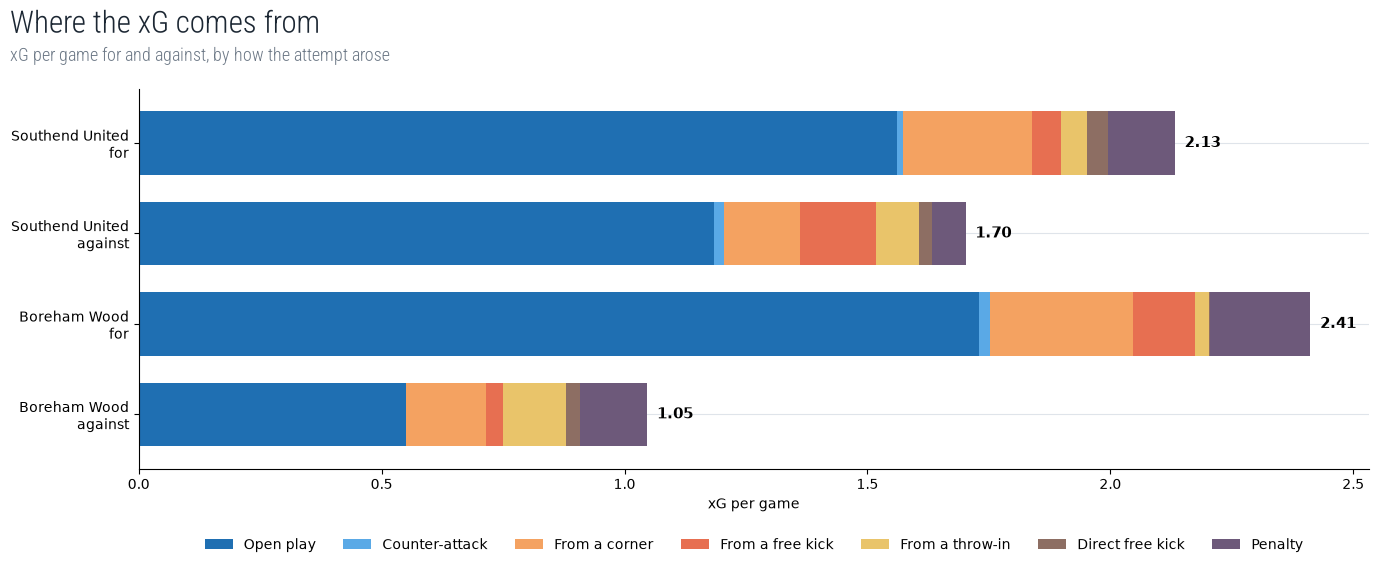

,Open play,Counter-attack,From a corner,From a free kick,From a throw-in,Direct free kick,Penalty
label,,,,,,,
Southend United\nfor,1.56,0.01,0.27,0.06,0.05,0.04,0.14
Southend United\nagainst,1.18,0.02,0.16,0.16,0.09,0.03,0.07
Boreham Wood\nfor,1.73,0.02,0.29,0.13,0.03,0.00,0.21
Boreham Wood\nagainst,0.55,0.00,0.16,0.04,0.13,0.03,0.14


In [47]:
SITUATIONS = ["Open play", "Counter-attack", "From a corner", "From a free kick", "From a throw-in",
              "Direct free kick", "Penalty"]
SIT_COLOURS = ["#1f6fb2", "#5aa9e6", "#f4a261", "#e76f51", "#e9c46a", "#8d6e63", "#6d597a"]


def xg_by_situation(events):
    totals = Counter()
    for e in filters.attempts(events, include_pens=True, include_free_kicks=True):
        totals[filters.situation(e)] += e["shot"]["xg"]
    return totals


rows = []
for t in TEAMS:
    for side, events in (("for", season_ours(t)), ("against", season_theirs(t))):
        totals = xg_by_situation(events)
        rows.append({"label": f"{NAME[t]}\n{side}", **{s: totals[s] / len(GAMES[t]) for s in SITUATIONS}})
situ = pd.DataFrame(rows).set_index("label")

fig, ax = plt.subplots(figsize=(14, 5))
situ.plot.barh(stacked=True, color=SIT_COLOURS, ax=ax, width=0.7)
for i, total in enumerate(situ.sum(axis=1)):
    ax.text(total + 0.02, i, f"{total:.2f}", va="center", fontsize=11, weight="bold")
ax.invert_yaxis()
ax.set_xlabel("xG per game")
ax.set_ylabel("")
ax.legend(ncol=7, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.15))
tidy(ax)
chart_title(fig, "Where the xG comes from", "xG per game for and against, by how the attempt arose")
plt.show()
situ.round(2)

## xG, match by match

Top: xG difference (xG minus xG against) in every game - the clearest single measure of
whether a team was the better side. The result is printed on each bar.
Bottom: cumulative goals (solid) against cumulative xG (dashed). Above the dashed line means
the finishing is running hot.

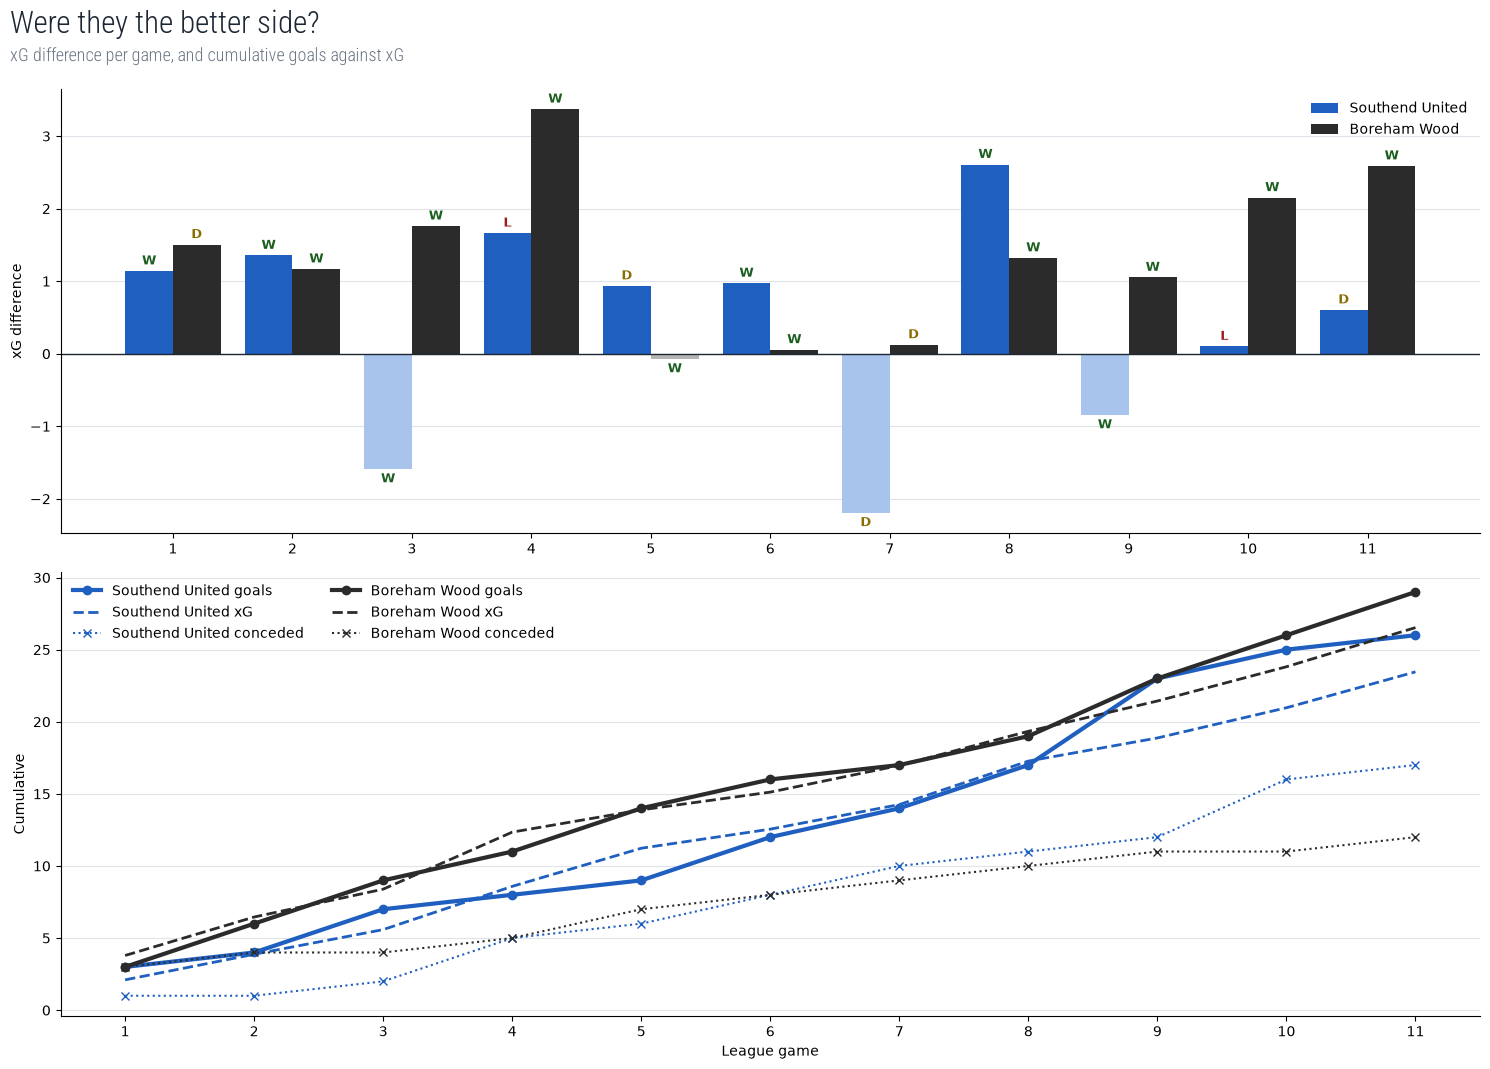

In [48]:
fig, (top, bottom) = plt.subplots(2, 1, figsize=(15, 10))
width = 0.4
for i, t in enumerate(TEAMS):
    d = per_match[per_match.team_id == t]
    xs = d.game + (i - 0.5) * width
    diff = d.xG - d.xGA
    top.bar(xs, diff, width=width, color=[COLOUR[t] if v >= 0 else LIGHT[t] for v in diff], label=NAME[t])
    for x, v, r in zip(xs, diff, d.result):
        top.text(x, v + (0.05 if v >= 0 else -0.05), r, ha="center", va="bottom" if v >= 0 else "top",
                 fontsize=9, color=RESULT_FG[r], weight="bold")
    bottom.plot(d.game, d.goals.cumsum(), color=COLOUR[t], lw=3, marker="o", label=f"{NAME[t]} goals")
    bottom.plot(d.game, d.xG.cumsum(), color=COLOUR[t], lw=2, ls="--", label=f"{NAME[t]} xG")
    bottom.plot(d.game, d.conceded.cumsum(), color=COLOUR[t], lw=1.5, ls=":", marker="x", label=f"{NAME[t]} conceded")
top.axhline(0, color=TEXT, lw=1)
top.set_ylabel("xG difference")
top.set_xticks(range(1, games + 1))
bottom.set_xticks(range(1, games + 1))
bottom.set_xlabel("League game")
bottom.set_ylabel("Cumulative")
top.legend(frameon=False)
bottom.legend(frameon=False, ncol=2)
for ax in (top, bottom):
    tidy(ax)
chart_title(fig, "Were they the better side?", "xG difference per game, and cumulative goals against xG")
fig.tight_layout()
plt.show()

---
# 4. Shape and territory

## Season average positions

Each player's mean position across the season - their own actions plus the spots where they
received a pass. The eleven players with the most minutes are solid and sized by minutes;
others who have played 270+ minutes (three full games) are hollow. The dashed lines mark the average height of
the back line and of the most advanced players.

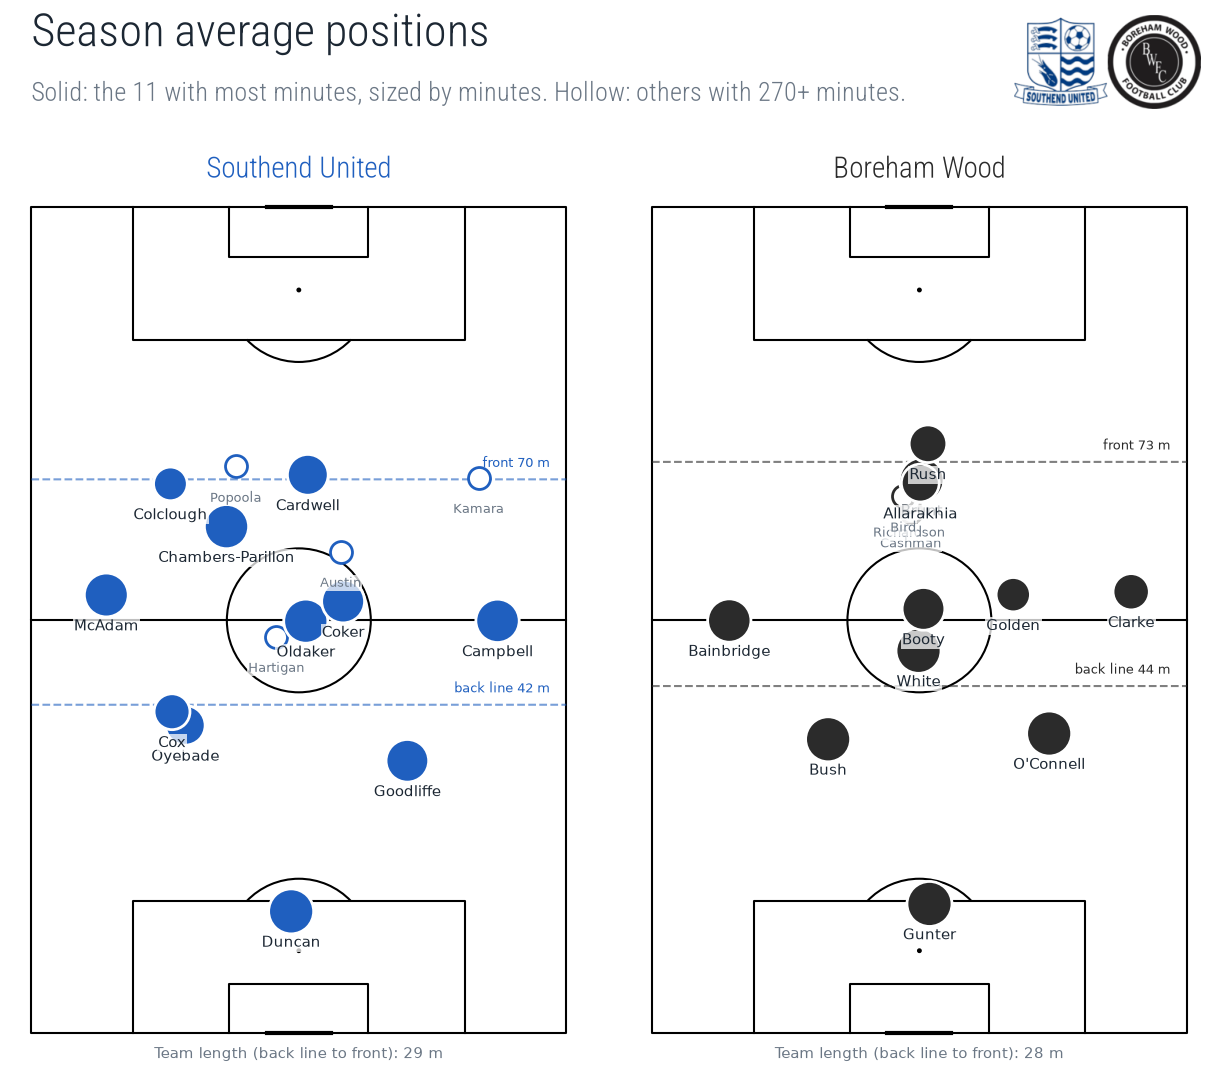

In [49]:
def season_positions(t):
    locs, names, minutes, starts = defaultdict(list), {}, Counter(), Counter()
    for m in GAMES[t]:
        details = get_match_details(m["summary"].match_id)
        formation = details["teamsData"][str(t)].get("formation") or {}
        for p in formation.get("lineup") or []:
            starts[p["playerId"]] += 1
        for p in (formation.get("lineup") or []) + (formation.get("bench") or []):
            minutes[p["playerId"]] += minutes_played(player_spells(p["playerId"], t, details))
        for e in ours(m, t):
            if not filters.has_location(e):
                continue
            locs[e["player"]["id"]].append(filters.location(e))
            names[e["player"]["id"]] = e["player"]["name"]
            if filters.primary(e) == "pass" and e["pass"]["accurate"] and e["pass"]["recipient"]:
                locs[e["pass"]["recipient"]["id"]].append(filters.end_location(e))
    rows = [{"player_id": pid, "name": names.get(pid, str(pid)), "x": np.mean([p[0] for p in pts]),
             "y": np.mean([p[1] for p in pts]), "minutes": minutes[pid], "starts": starts[pid], "touches": len(pts)}
            for pid, pts in locs.items() if minutes[pid] > 0]
    return pd.DataFrame(rows).sort_values("minutes", ascending=False).reset_index(drop=True)


POSITIONS = {t: season_positions(t) for t in TEAMS}

fig, axes, pitch = two_pitches("Season average positions",
                               "Solid: the 11 with most minutes, sized by minutes. Hollow: others with 270+ minutes.",
                               fig_height=11)
for t, ax in axes.items():
    df = POSITIONS[t]
    core, rest = df.head(11), df.iloc[11:][df.iloc[11:].minutes >= 270]
    pitch.scatter(rest.x, rest.y, s=250, facecolor="white", edgecolor=COLOUR[t], lw=2, ax=ax, zorder=3)
    pitch.scatter(core.x, core.y, s=core.minutes / core.minutes.max() * 900 + 150, color=COLOUR[t],
                  edgecolor="white", lw=2, ax=ax, zorder=4)
    for group, size, colour in ((core, 11, TEXT), (rest, 9, MUTED)):
        for _, p in group.iterrows():
            pitch.annotate(surname(p["name"]), (p.x - 3.8, p.y), ax=ax, ha="center", va="center", fontsize=size,
                           color=colour, zorder=5, bbox={"facecolor": "white", "alpha": 0.75, "pad": 1, "lw": 0})
    outfield = core[core.x > core.x.min() + 1]  # drop the keeper
    back_line = outfield.nsmallest(4, "x").x.mean()
    front_line = outfield.nlargest(2, "x").x.mean()
    for height, label in ((back_line, "back line"), (front_line, "front")):
        pitch.lines(height, 0, height, 100, ls="--", color=COLOUR[t], lw=1.5, alpha=0.6, ax=ax)
        pitch.annotate(f"{label} {height * 1.05:.0f} m", (height + 1.5, 97), ax=ax, fontsize=9, color=COLOUR[t], ha="right")
    ax.text(50, -3, f"Team length (back line to front): {(front_line - back_line) * 1.05:.0f} m", ha="center",
            fontsize=11, color=MUTED)
plt.show()

## Where each team has the ball

Share of each team's touches in the 18 zones of the pitch, attacking upwards. Darker means a
bigger share of the team's play happens there.

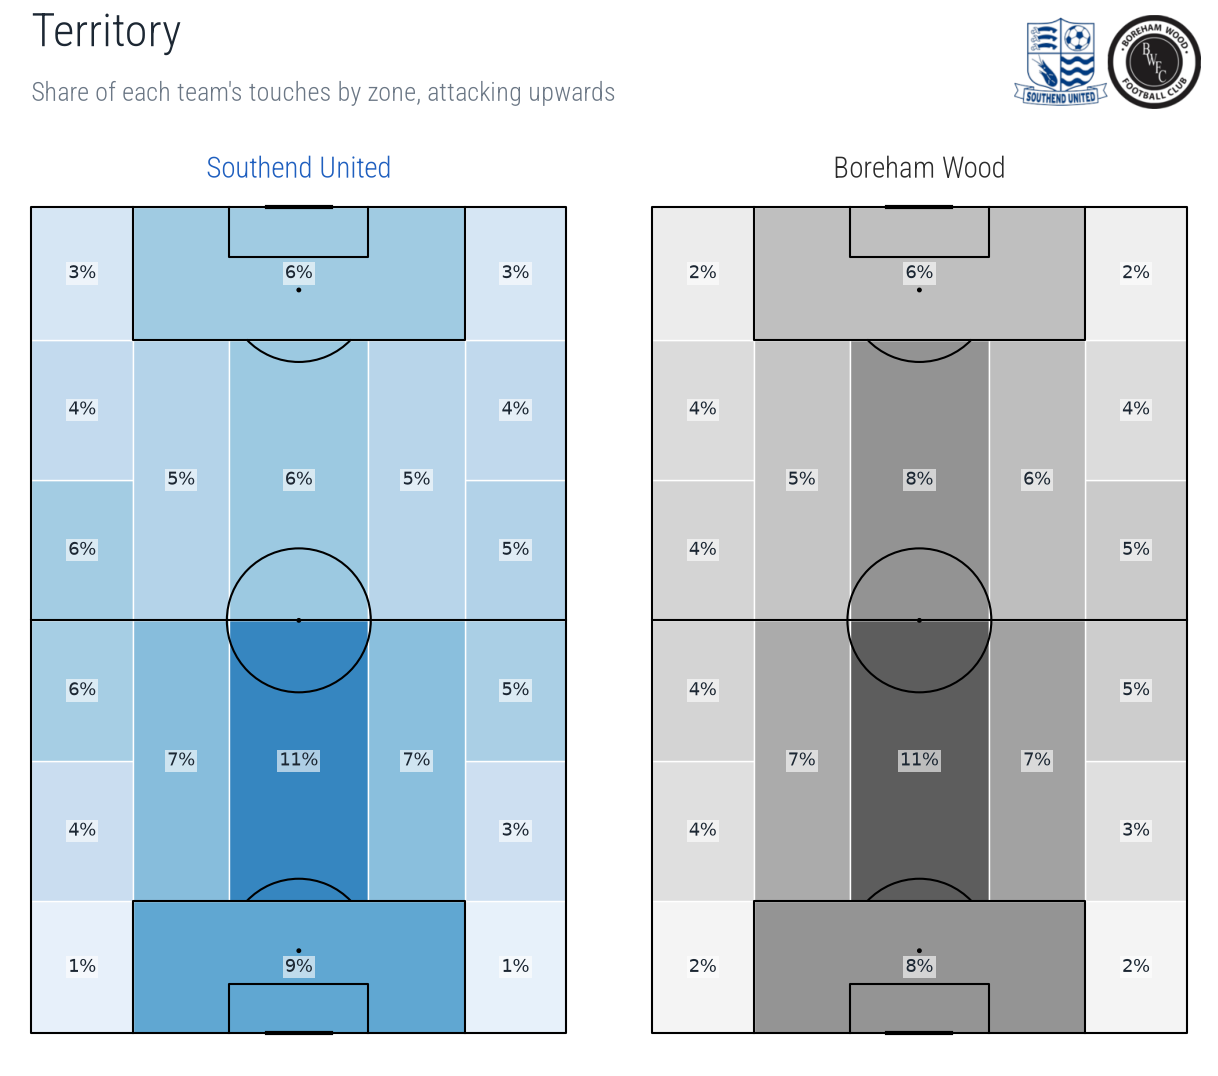

In [50]:
fig, axes, pitch = two_pitches("Territory", "Share of each team's touches by zone, attacking upwards", fig_height=11)
for t, ax in axes.items():
    xs, ys = xy(season_ours(t))
    stats = pitch.bin_statistic_positional(xs, ys, statistic="count", positional="full", normalize=True)
    pitch.heatmap_positional(stats, ax=ax, cmap=CMAP[t], edgecolors="white", vmin=0, vmax=0.16)
    pitch.label_heatmap(stats, ax=ax, str_format="{:.0%}", fontsize=13, color=TEXT, ha="center", va="center",
                        exclude_zeros=True, path_effects=None,
                        bbox={"facecolor": "white", "alpha": 0.6, "pad": 1.5, "lw": 0})
plt.show()

## Field tilt and possession, match by match

Field tilt (share of final-third touches) shows who pinned whom back; possession shows who had
the ball. Big tilt with modest possession is a direct, front-foot team.

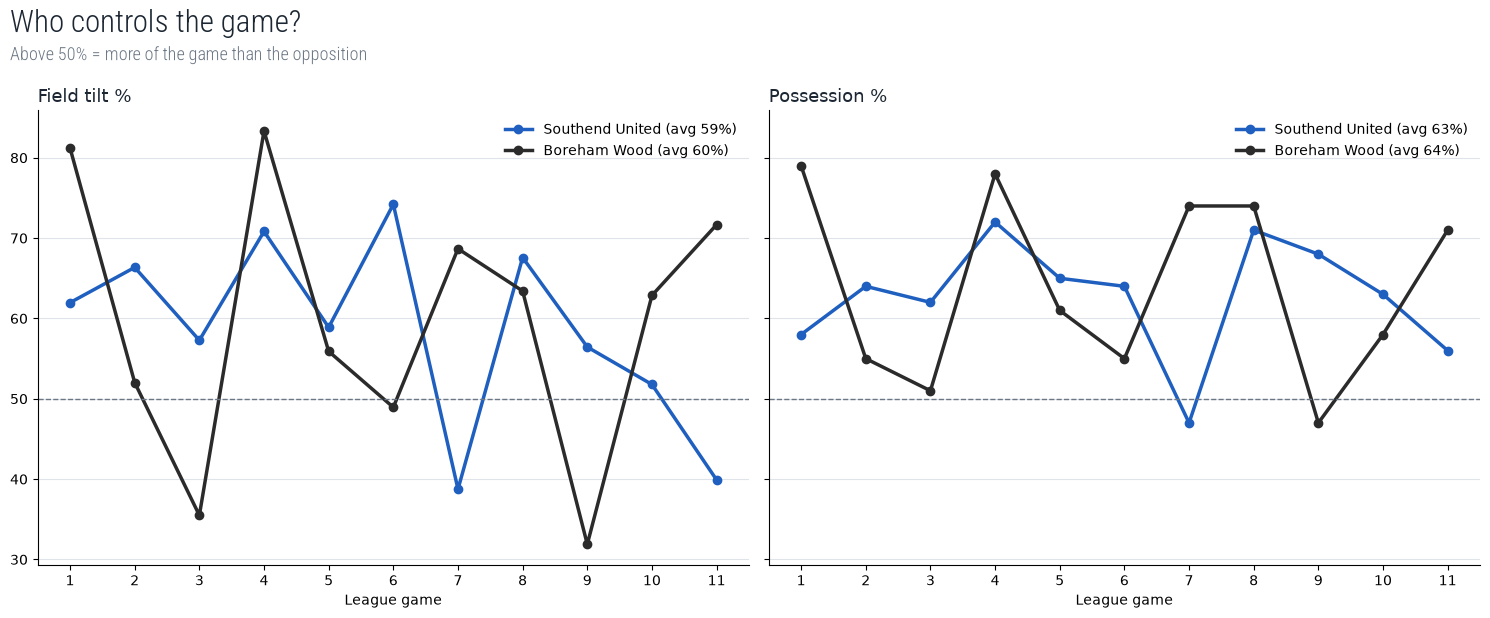

In [51]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
for ax, col, title in zip(axs, ["field_tilt", "possession"], ["Field tilt %", "Possession %"]):
    for t in TEAMS:
        d = per_match[per_match.team_id == t]
        ax.plot(d.game, d[col], color=COLOUR[t], marker="o", lw=2.5, label=f"{NAME[t]} (avg {d[col].mean():.0f}%)")
    ax.axhline(50, color=MUTED, lw=1, ls="--")
    ax.set_title(title, loc="left", fontsize=13, color=TEXT)
    ax.set_xlabel("League game")
    ax.set_xticks(range(1, games + 1))
    ax.legend(frameon=False)
    tidy(ax)
chart_title(fig, "Who controls the game?", "Above 50% = more of the game than the opposition")
plt.show()

---
# 5. Duels

## Duel success by type

Win rate for each kind of duel, with the number contested per game on each bar. An aerial duel
has one winner, so 50% is break-even there. A ground duel can count as won for both players
(the attacker keeps the ball, the defender stops him going forward), so those rates run higher.

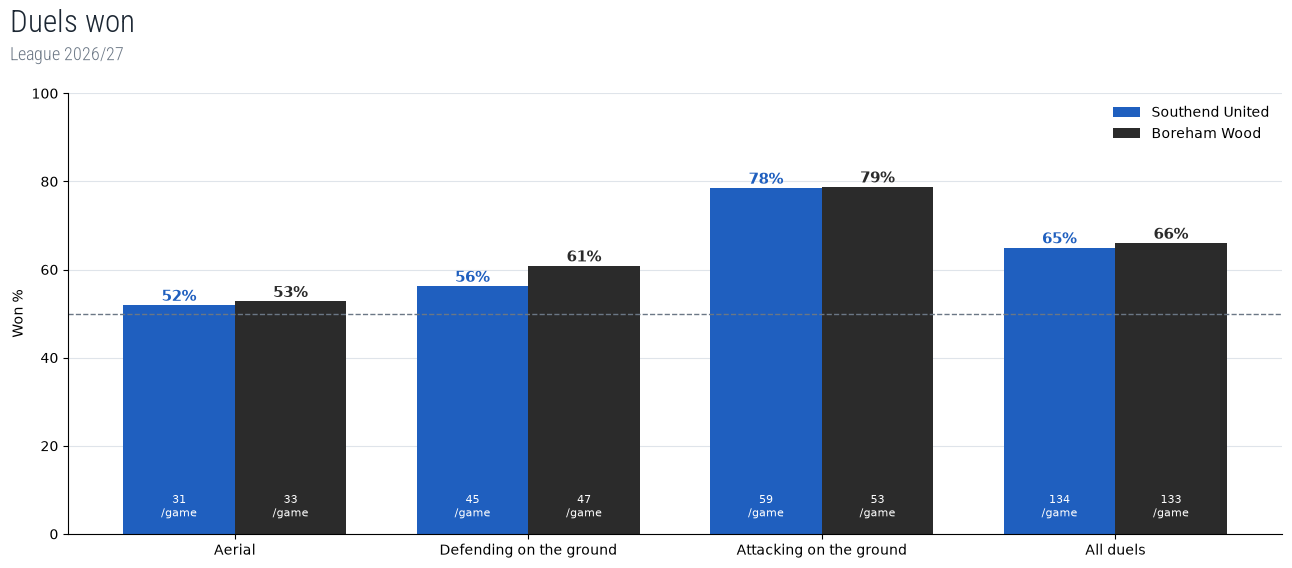

In [52]:
DUEL_TYPES = [("aerial", "Aerial"), ("defensive", "Defending on the ground"), ("offensive", "Attacking on the ground"),
              (None, "All duels")]
fig, ax = plt.subplots(figsize=(13, 5))
width = 0.38
for i, t in enumerate(TEAMS):
    events = season_ours(t)
    groups = [contested_duels(events, k) for k, _ in DUEL_TYPES]
    rates = [pct(sum(filters.duel_won(d) for d in g), len(g)) for g in groups]
    xs = np.arange(len(groups)) + (i - 0.5) * width
    ax.bar(xs, rates, width=width, color=COLOUR[t], label=NAME[t])
    for x, r, g in zip(xs, rates, groups):
        ax.text(x, r + 1, f"{r:.0f}%", ha="center", fontsize=11, weight="bold", color=COLOUR[t])
        ax.text(x, 4, f"{len(g) / len(GAMES[t]):.0f}\n/game", ha="center", fontsize=8, color="white")
ax.set_xticks(range(len(DUEL_TYPES)), [label for _, label in DUEL_TYPES])
ax.set_ylim(0, 100)
ax.set_ylabel("Won %")
ax.axhline(50, color=MUTED, ls="--", lw=1)
ax.legend(frameon=False)
tidy(ax)
chart_title(fig, "Duels won", f"League {LABEL}")
plt.show()

## Where duels are won and lost

The pitch split into a 6 x 4 grid, attacking upwards. Each zone shows the win rate of the
team's duels there, with the number contested underneath. The colour is centred on the
two teams' overall rate: green is better than that, red worse.
Weak zones at the back are where opponents get joy; strong zones high up feed the press.

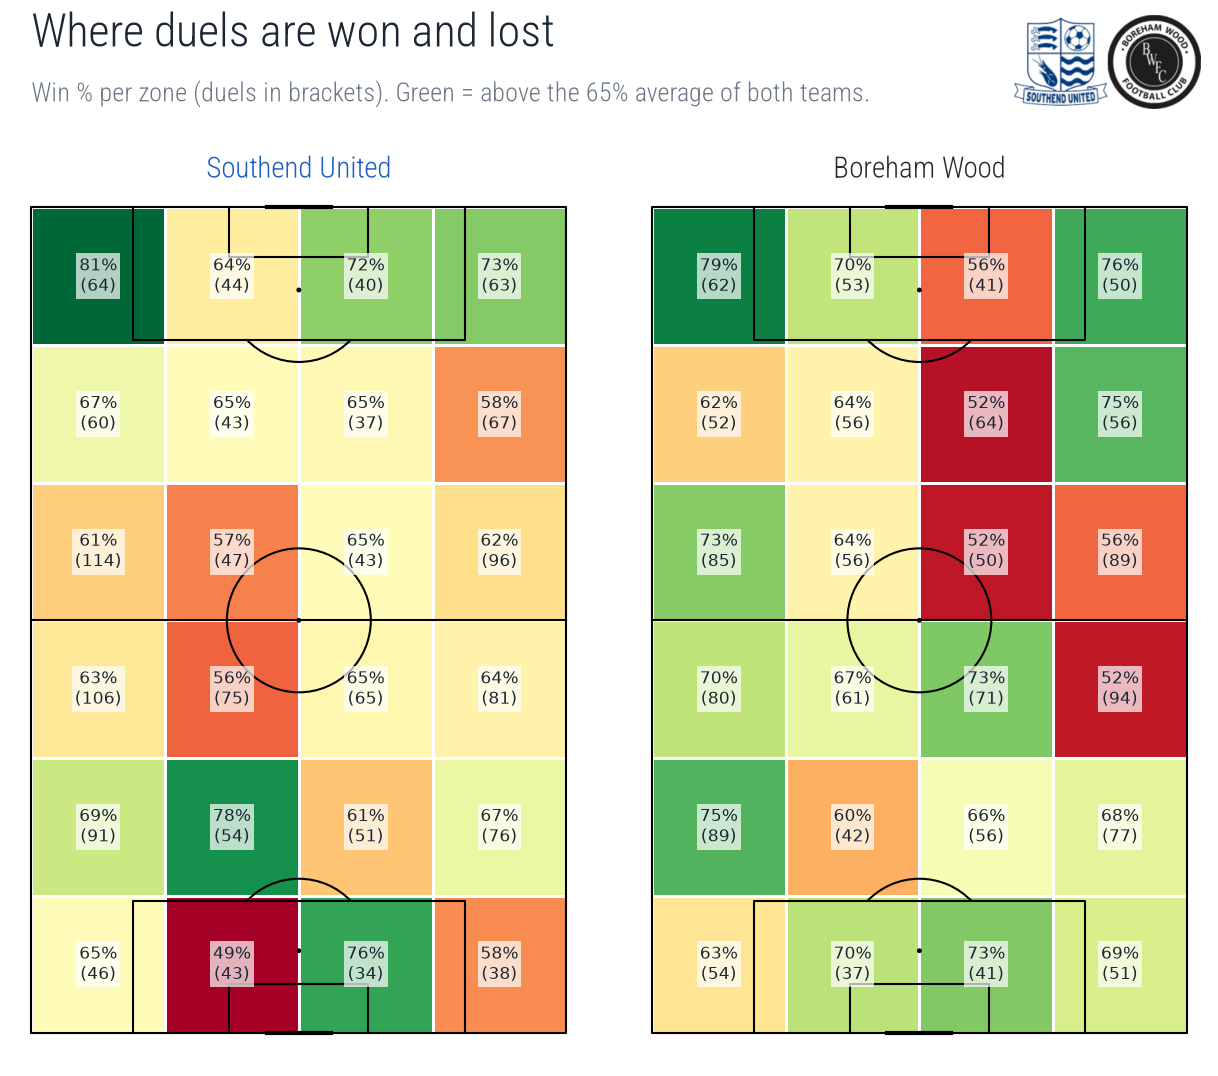

In [53]:
centre = np.mean([filters.duel_won(d) for t in TEAMS for d in contested_duels(season_ours(t))])
fig, axes, pitch = two_pitches("Where duels are won and lost",
                               f"Win % per zone (duels in brackets). Green = above the {centre:.0%} average of both teams.",
                               fig_height=11)
for t, ax in axes.items():
    duels = [d for d in contested_duels(season_ours(t)) if filters.has_location(d)]
    xs, ys = xy(duels)
    won = np.array([filters.duel_won(d) for d in duels], dtype=float)
    stats = pitch.bin_statistic(xs, ys, values=won, statistic="mean", bins=(6, 4))
    counts = pitch.bin_statistic(xs, ys, statistic="count", bins=(6, 4))
    pitch.heatmap(stats, ax=ax, cmap="RdYlGn", vmin=centre - 0.15, vmax=centre + 0.15, edgecolors="white")
    for cx, cy, v, n in zip(stats["cx"].ravel(), stats["cy"].ravel(), stats["statistic"].ravel(), counts["statistic"].ravel()):
        if n:
            pitch.annotate(f"{v:.0%}\n({int(n)})", (cx, cy), ax=ax, ha="center", va="center", fontsize=12, color=TEXT,
                           bbox={"facecolor": "white", "alpha": 0.7, "pad": 2, "lw": 0})
plt.show()

## Aerial duels

Every aerial duel: filled = won, cross = lost. Clusters around our own box are defending set
pieces and long balls; clusters high up are the target man at work.

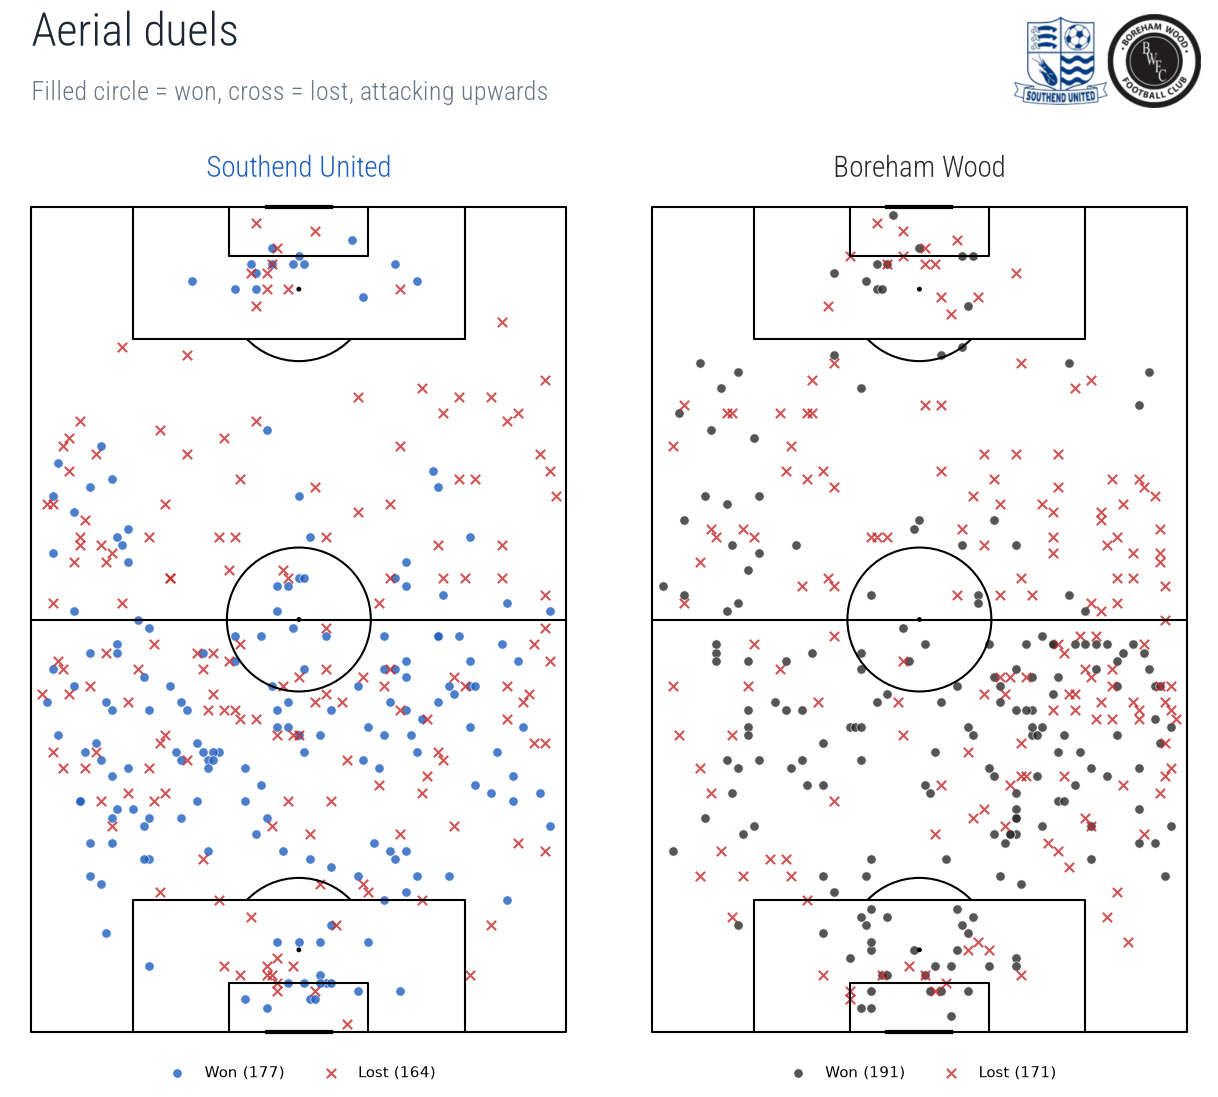

In [54]:
fig, axes, pitch = two_pitches("Aerial duels", "Filled circle = won, cross = lost, attacking upwards", fig_height=11)
for t, ax in axes.items():
    aerials = [d for d in filters.duels(season_ours(t), "aerial") if filters.has_location(d)]
    won = [d for d in aerials if filters.duel_won(d)]
    lost = [d for d in aerials if not filters.duel_won(d)]
    if won:
        pitch.scatter(*xy(won), s=45, color=COLOUR[t], edgecolor="white", lw=0.5, ax=ax, alpha=0.8,
                      label=f"Won ({len(won)})")
    if lost:
        pitch.scatter(*xy(lost), s=45, marker="x", color="#c62828", lw=1.5, ax=ax, alpha=0.8, label=f"Lost ({len(lost)})")
    ax.legend(loc="lower center", ncol=2, frameon=False, fontsize=11, bbox_to_anchor=(0.5, -0.06))
plt.show()

---
# 6. Chance creation

## Key passes and shot assists

Every pass that set up an attempt (corners and free-kick deliveries included). Red arrows are
assists for a goal.

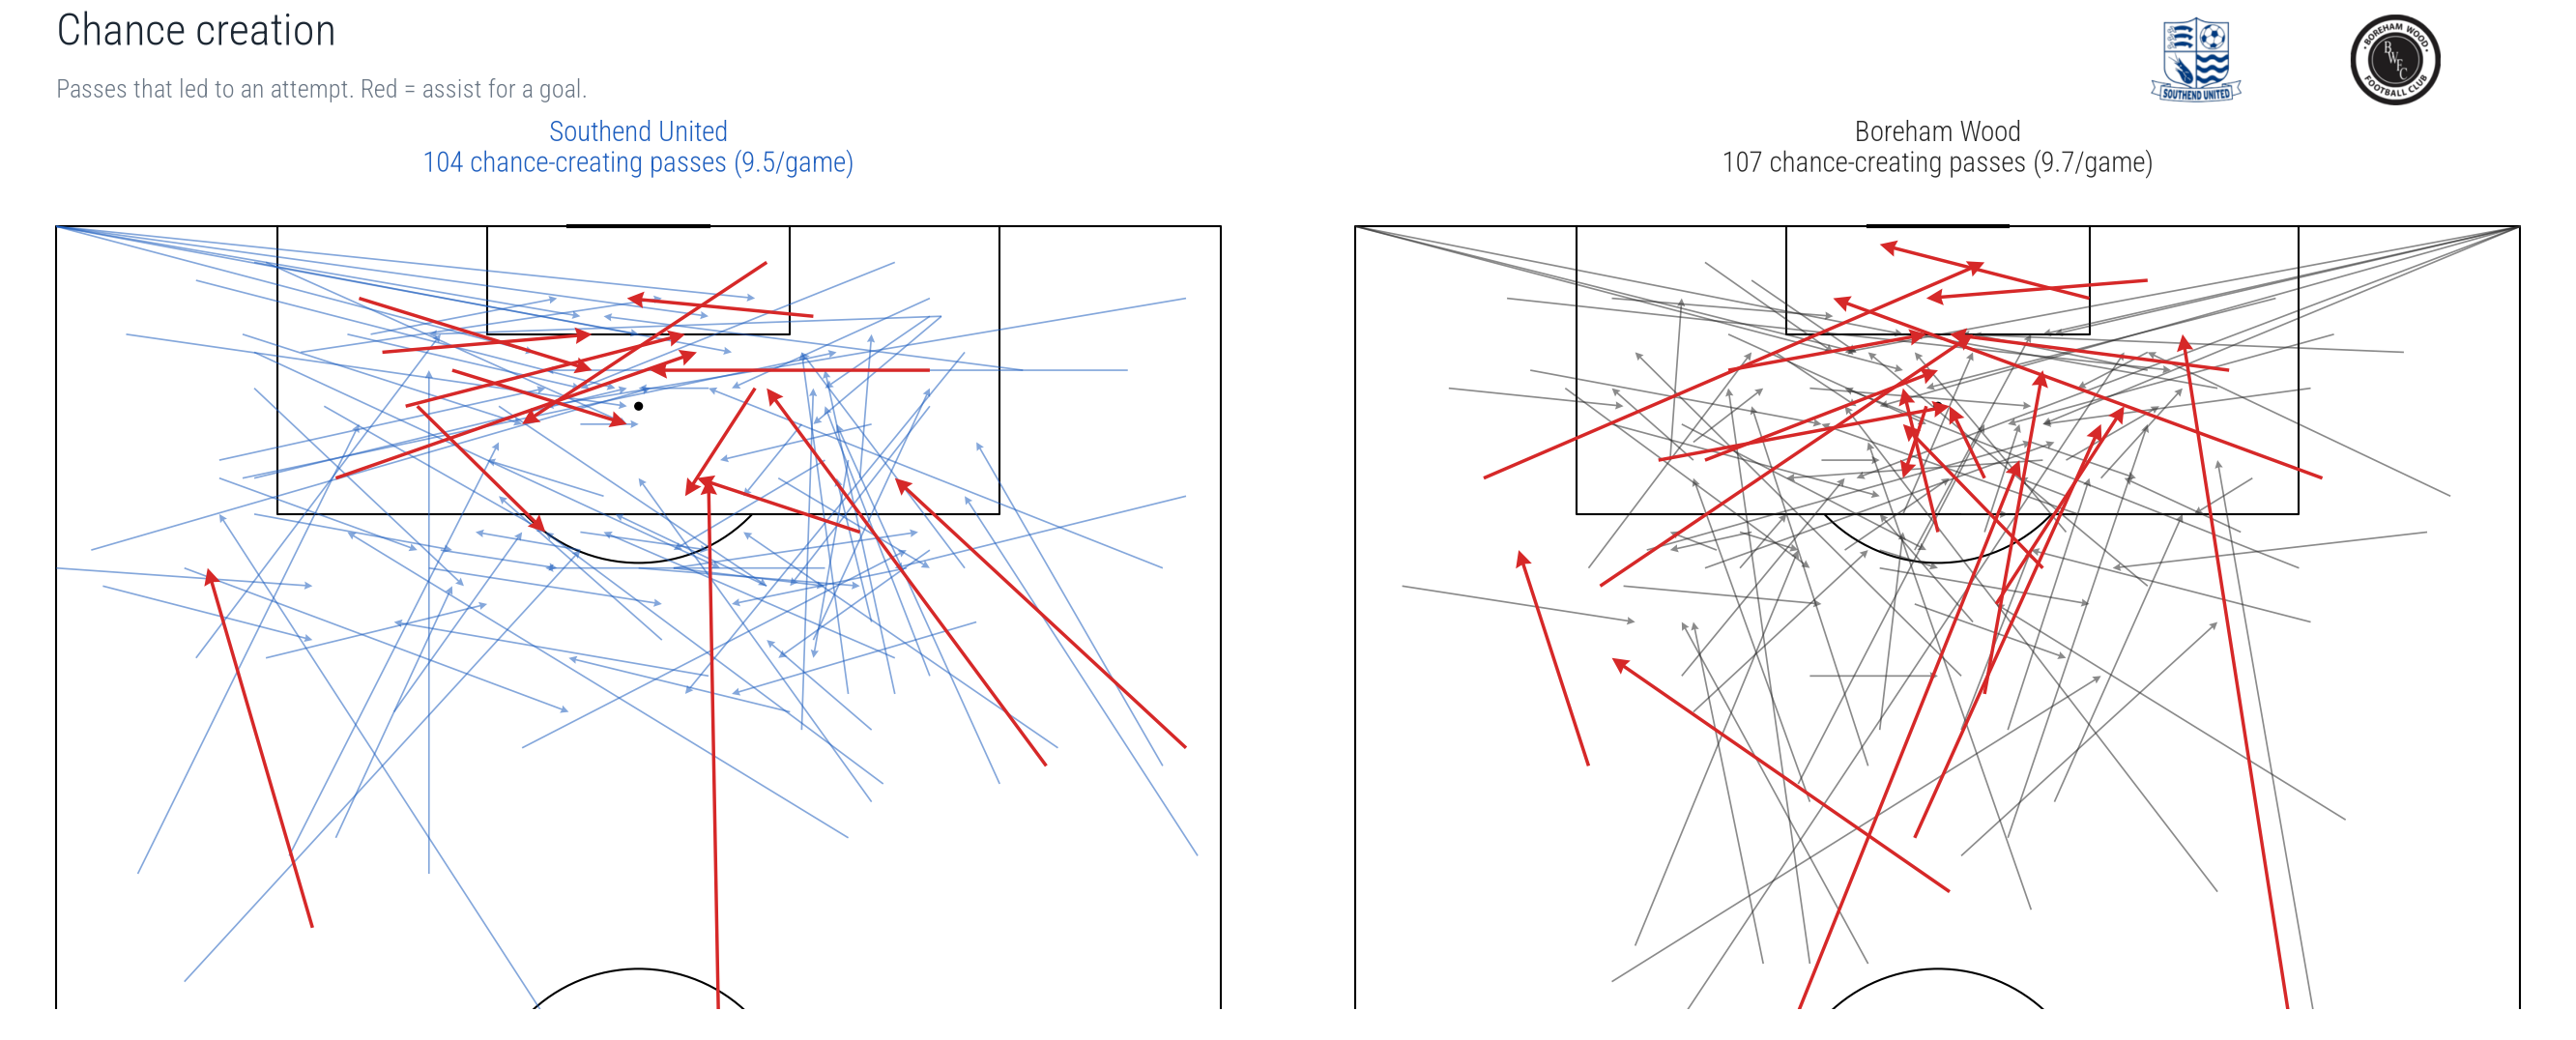

In [55]:
def chance_passes(t):
    return [e for e in season_ours(t) if e.get("pass") and filters.has_location(e)
            and filters.end_location(e) != [0, 0]
            and {"shot_assist", "key_pass", "assist"} & set(filters.secondary(e))]


titles = {t: f"{NAME[t]}\n{len(chance_passes(t))} chance-creating passes ({len(chance_passes(t)) / len(GAMES[t]):.1f}/game)"
          for t in TEAMS}
fig, axes, pitch = two_pitches("Chance creation", "Passes that led to an attempt. Red = assist for a goal.",
                               half=True, fig_height=11, panel_titles=titles)
for t, ax in axes.items():
    passes = chance_passes(t)
    for e in passes:
        assist = "assist" in filters.secondary(e)
        (x0, y0), (x1, y1) = filters.location(e), filters.end_location(e)
        pitch.arrows(x0, y0, x1, y1, ax=ax, width=2.5 if assist else 1.2, headwidth=5, headlength=5,
                     color="#d62828" if assist else COLOUR[t], alpha=1 if assist else 0.55, zorder=4 if assist else 3)
plt.show()

## Where the final ball comes from

The same passes counted by zone of origin, as a share of each team's total. Wide zones heavy?
A crossing team. Central zone 14 (just outside the box) heavy? A team that plays through the
middle.

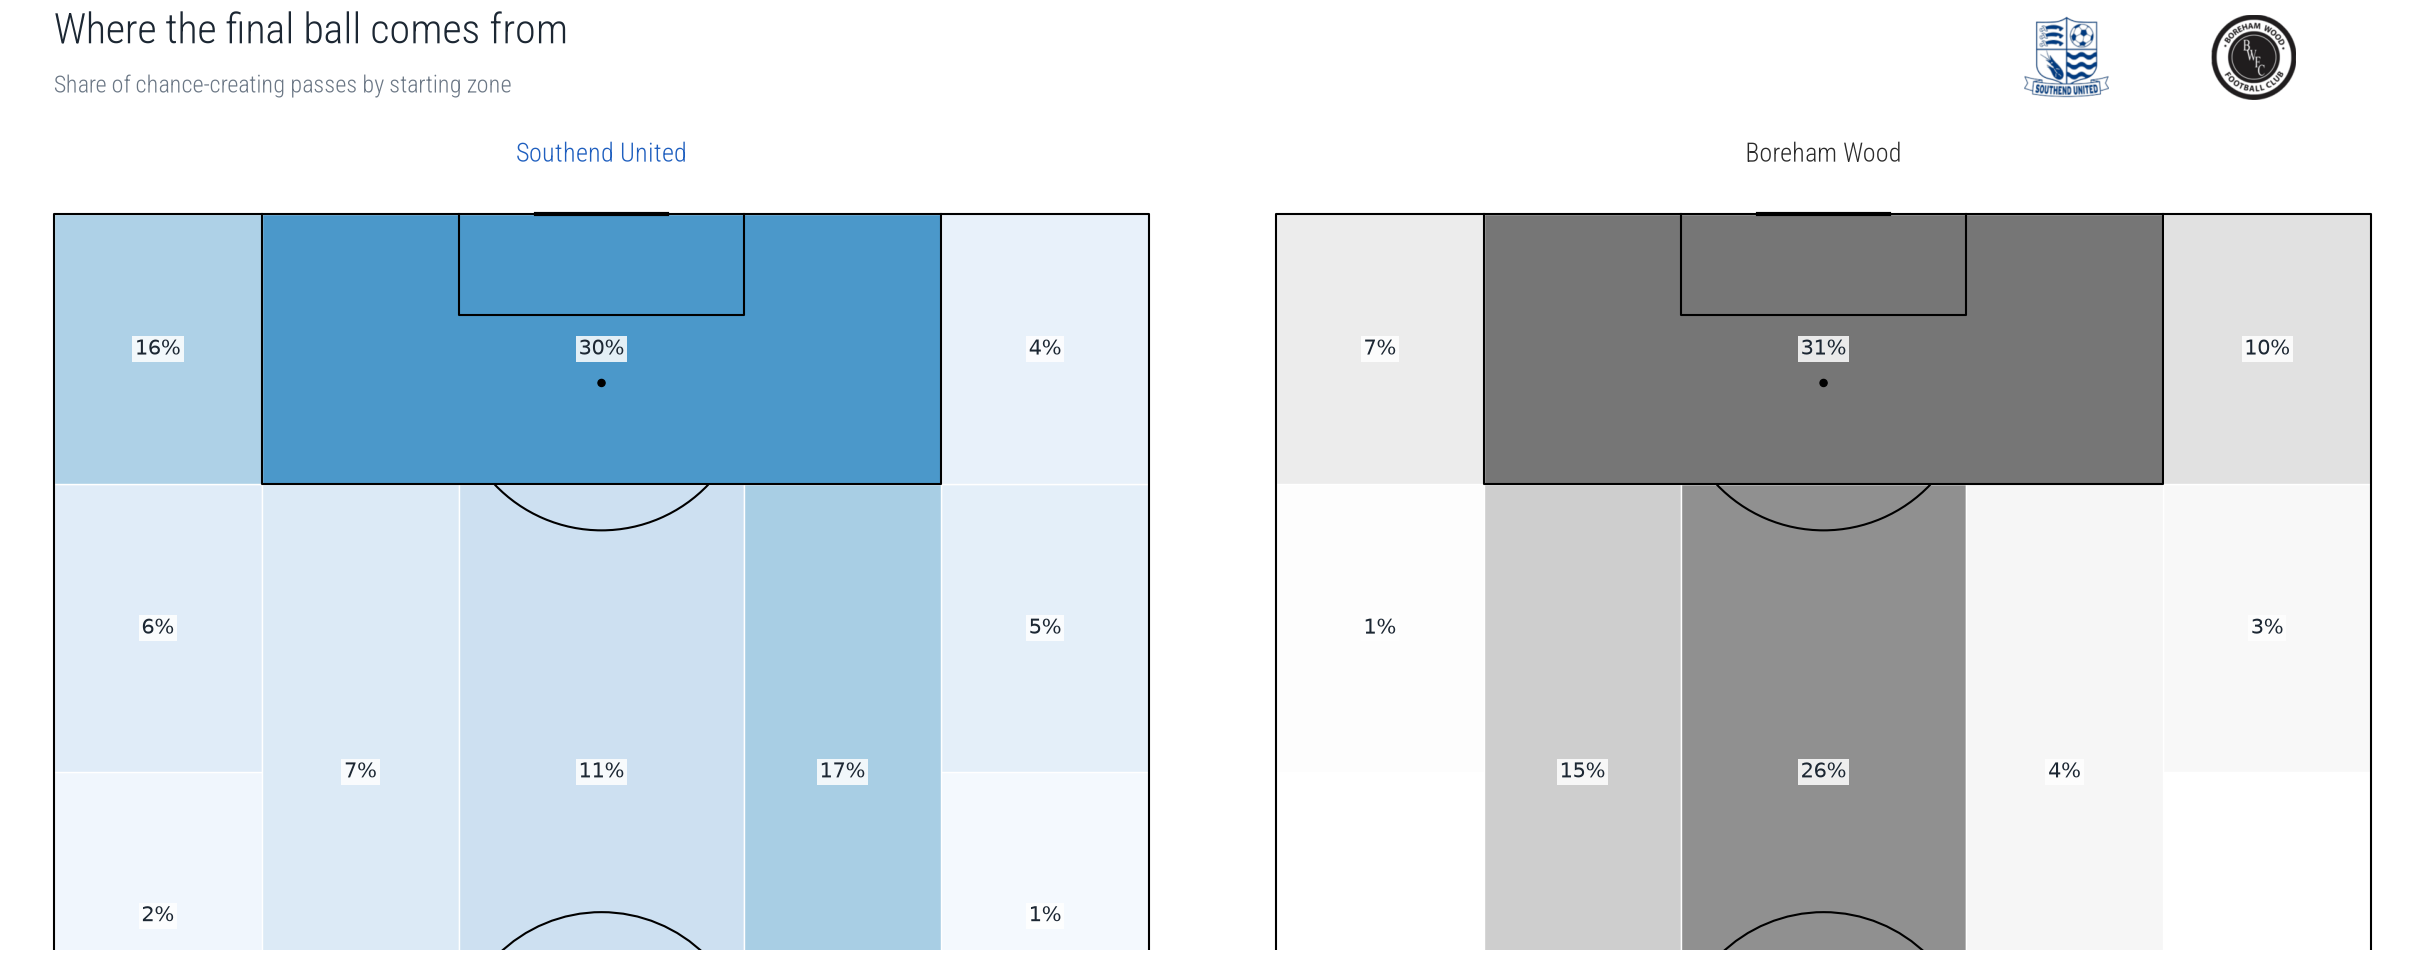

In [56]:
fig, axes, pitch = two_pitches("Where the final ball comes from", "Share of chance-creating passes by starting zone",
                               half=True, fig_height=10)
for t, ax in axes.items():
    xs, ys = xy(chance_passes(t))
    stats = pitch.bin_statistic_positional(xs, ys, statistic="count", positional="full", normalize=True)
    pitch.heatmap_positional(stats, ax=ax, cmap=CMAP[t], edgecolors="white", vmin=0, vmax=0.5)
    pitch.label_heatmap(stats, ax=ax, str_format="{:.0%}", fontsize=15, color=TEXT, ha="center", va="center",
                        exclude_zeros=True, path_effects=None,
                        bbox={"facecolor": "white", "alpha": 0.85, "pad": 2, "lw": 0})
plt.show()

## Who creates?

Chance-creating passes per player (top 8 each), with the number that became goal assists.

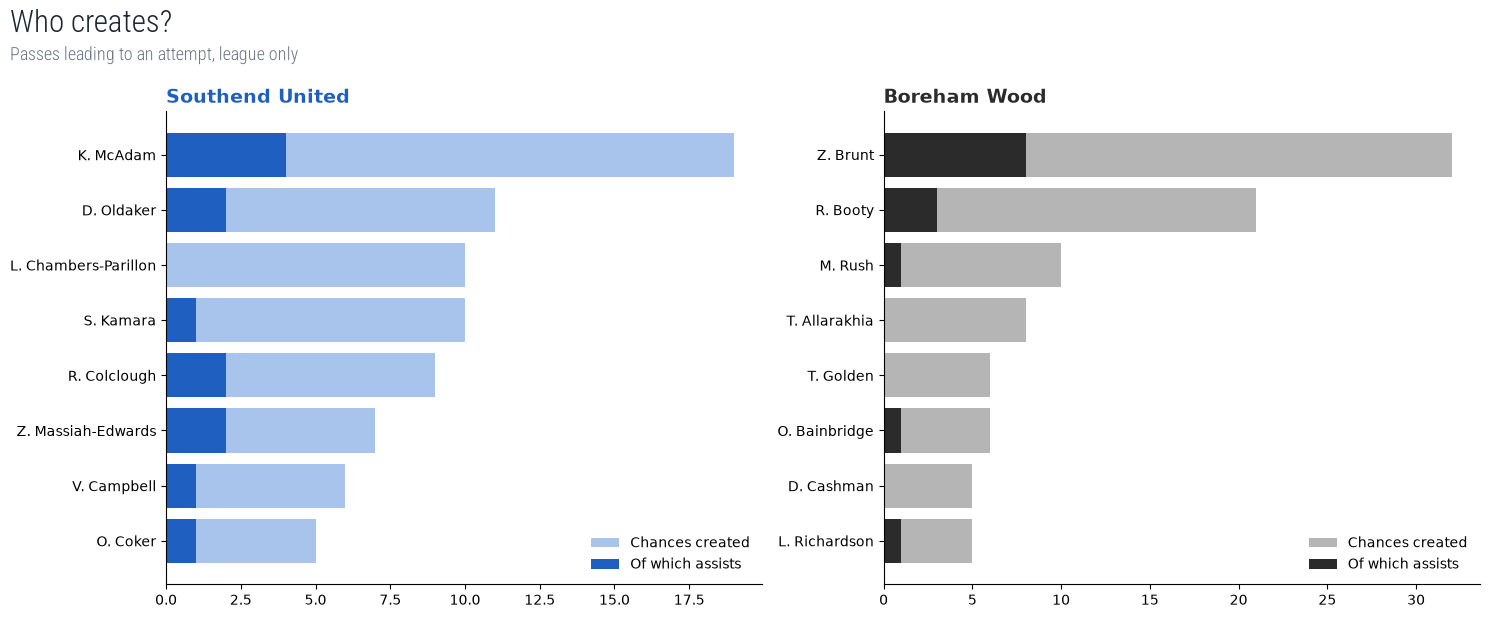

In [57]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, t in zip(axs, TEAMS):
    passes = chance_passes(t)
    created = Counter(e["player"]["name"] for e in passes).most_common(8)
    assists = Counter(e["player"]["name"] for e in passes if "assist" in filters.secondary(e))
    names = [n for n, _ in created][::-1]
    ax.barh(names, [c for _, c in created][::-1], color=LIGHT[t], label="Chances created")
    ax.barh(names, [assists[n] for n in names], color=COLOUR[t], label="Of which assists")
    ax.set_title(NAME[t], loc="left", color=COLOUR[t], fontsize=14, weight="bold")
    ax.legend(frameon=False, loc="lower right")
    ax.spines[["top", "right"]].set_visible(False)
chart_title(fig, "Who creates?", "Passes leading to an attempt, league only")
plt.show()

---
# 7. Pressing and winning the ball back

## Where the ball is won back

Density of every recovery (interceptions, tackles and loose balls won) attacking upwards. A
team that presses high wins the ball nearer the opposition goal - and those recoveries are
short, quick routes to a shot.

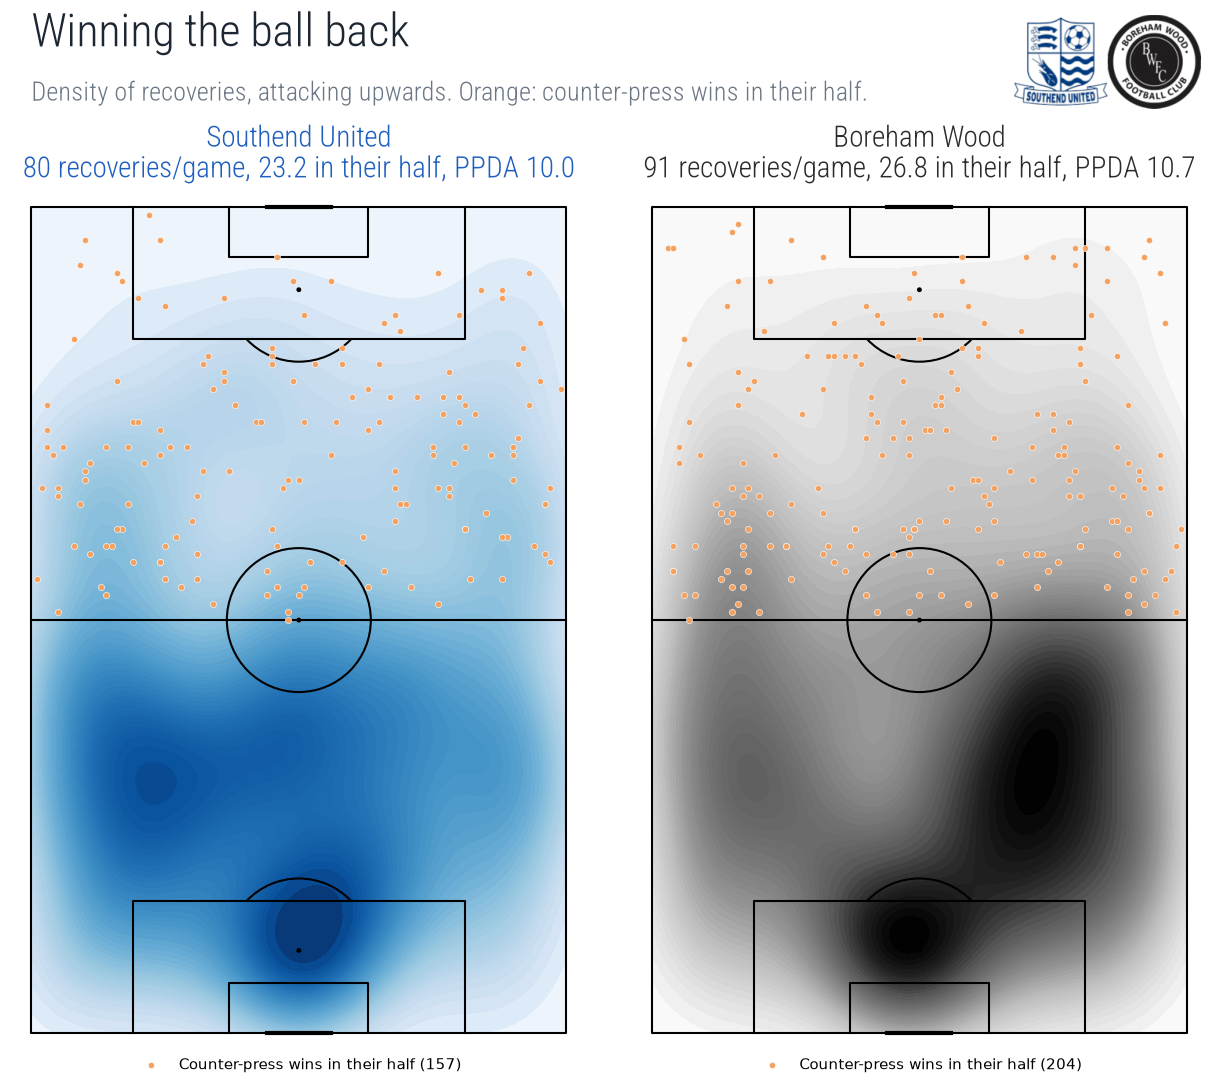

In [58]:
titles = {}
for t in TEAMS:
    d = per_match[per_match.team_id == t]
    titles[t] = (f"{NAME[t]}\n{d.recoveries.mean():.0f} recoveries/game, {d.high_recoveries.mean():.1f} in their half, "
                 f"PPDA {d.ppda.mean():.1f}")
fig, axes, pitch = two_pitches("Winning the ball back", "Density of recoveries, attacking upwards. Orange: counter-press wins in their half.",
                               fig_height=11, panel_titles=titles)
for t, ax in axes.items():
    recoveries = [e for e in season_ours(t) if "recovery" in filters.secondary(e) and filters.has_location(e)]
    pitch.kdeplot(*xy(recoveries), ax=ax, fill=True, levels=50, thresh=0, cmap=CMAP[t])
    high = [e for e in recoveries if "counterpressing_recovery" in filters.secondary(e) and e["location"]["x"] >= 50]
    pitch.scatter(*xy(high), s=20, color="#f4a261", edgecolor="white", lw=0.4, ax=ax, zorder=3,
                  label=f"Counter-press wins in their half ({len(high)})")
    ax.legend(loc="lower center", frameon=False, fontsize=11, bbox_to_anchor=(0.5, -0.05))
plt.show()

## Pressing intensity through the season

PPDA per game (lower = more aggressive press; the axis is flipped so up is more intense) next
to recoveries in the opposition half.

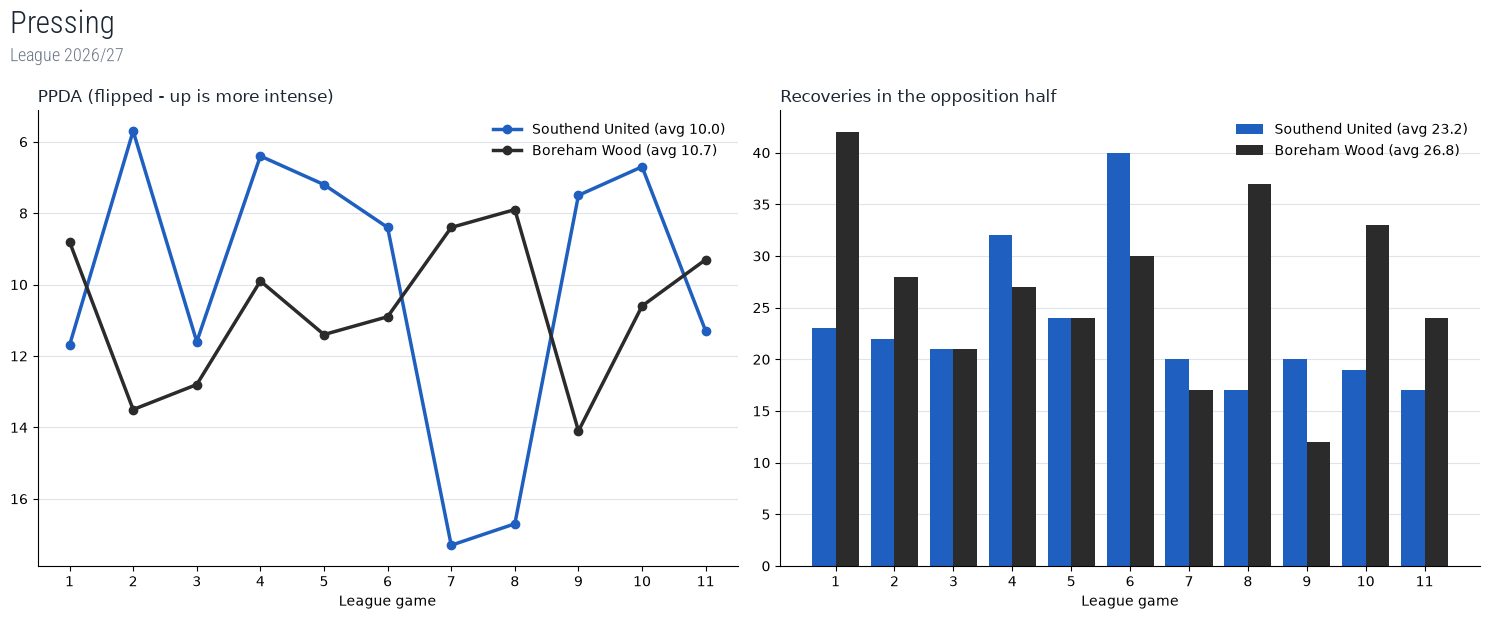

In [59]:
fig, (left, right) = plt.subplots(1, 2, figsize=(15, 5.5))
for i, t in enumerate(TEAMS):
    d = per_match[per_match.team_id == t]
    left.plot(d.game, d.ppda, color=COLOUR[t], marker="o", lw=2.5, label=f"{NAME[t]} (avg {d.ppda.mean():.1f})")
    right.bar(d.game + (i - 0.5) * 0.4, d.high_recoveries, width=0.4, color=COLOUR[t],
              label=f"{NAME[t]} (avg {d.high_recoveries.mean():.1f})")
left.invert_yaxis()
left.set_title("PPDA (flipped - up is more intense)", loc="left", color=TEXT)
right.set_title("Recoveries in the opposition half", loc="left", color=TEXT)
for ax in (left, right):
    ax.set_xlabel("League game")
    ax.set_xticks(range(1, games + 1))
    ax.legend(frameon=False)
    tidy(ax)
chart_title(fig, "Pressing", f"League {LABEL}")
plt.show()

---
# 8. Strikers

## Finishing efficiency

Every player whose most common position this season is centre forward (or second striker),
with 90+ league minutes. Penalties are counted in goals and xG, and split out as npxG.

- **Conversion** - goals per attempt.
- **Goals - xG** - positive means finishing better than the chances deserved.
- **Big chances** - attempts worth 0.3 xG or more.

In [60]:
STRIKER_POSITIONS = {"CF", "LCF", "RCF", "SS"}


def striker_table(t):
    events = season_ours(t)
    by_player = defaultdict(list)
    for e in events:
        by_player[e["player"]["id"]].append(e)
    minutes = POSITIONS[t].set_index("player_id").minutes
    rows = []
    for pid, evs in by_player.items():
        position = Counter(e["player"]["position"] for e in evs).most_common(1)[0][0]
        mins = minutes.get(pid, 0)
        if position not in STRIKER_POSITIONS or mins < 90:
            continue
        shots = filters.attempts(evs, include_pens=True, include_free_kicks=True)
        pens = [s for s in shots if filters.primary(s) == "penalty"]
        big = [s for s in shots if is_big_chance(s)]
        aerials = filters.duels(evs, "aerial")
        goals = sum(1 for s in shots if s["shot"]["isGoal"])
        xg = sum(s["shot"]["xg"] for s in shots)
        per90 = 90 / mins
        rows.append({
            "team_id": t, "team": NAME[t], "player_id": pid, "player": evs[0]["player"]["name"],
            "minutes": mins, "goals": goals, "xG": round(xg, 2),
            "npxG": round(xg - sum(s["shot"]["xg"] for s in pens), 2),
            "attempts": len(shots), "on_target": sum(1 for s in shots if s["shot"]["onTarget"]),
            "big_chances": len(big), "big_chances_scored": sum(1 for s in big if s["shot"]["isGoal"]),
            "box_touches": sum(1 for e in evs if "touch_in_box" in filters.secondary(e)),
            "goals_90": goals * per90, "xG_90": xg * per90, "attempts_90": len(shots) * per90,
            "xG_per_shot": xg / len(shots) if shots else 0, "conversion": pct(goals, len(shots)),
            "on_target_pct": pct(sum(1 for s in shots if s["shot"]["onTarget"]), len(shots)),
            "goals_minus_xG": goals - xg,
            "aerials_won_pct": pct(sum(filters.duel_won(d) for d in aerials), len(aerials)),
            "shots": shots,
        })
    return pd.DataFrame(rows)


STRIKERS = pd.concat([striker_table(t) for t in TEAMS], ignore_index=True)
(STRIKERS.drop(columns=["team_id", "player_id", "shots"])
 .sort_values(["team", "minutes"], ascending=[False, False])
 .style.format(precision=2).format("{:.0f}", subset=["minutes", "conversion", "on_target_pct", "aerials_won_pct"])
 .background_gradient(cmap="RdYlGn", subset=["goals_90", "xG_90", "conversion", "goals_minus_xG", "xG_per_shot"])
 .hide(axis="index"))

team,player,minutes,goals,xG,npxG,attempts,on_target,big_chances,big_chances_scored,box_touches,goals_90,xG_90,attempts_90,xG_per_shot,conversion,on_target_pct,goals_minus_xG,aerials_won_pct
Southend United,H. Cardwell,641,4,4.18,3.42,19,11,4,2,34,0.56,0.59,2.67,0.22,21,58,-0.18,48
Southend United,P. Omochere,187,3,2.42,2.42,14,5,1,0,26,1.44,1.16,6.74,0.17,21,36,0.58,50
Southend United,C. Kendall,136,1,0.36,0.36,4,1,0,0,4,0.66,0.24,2.65,0.09,25,25,0.64,23
Boreham Wood,M. Rush,584,9,6.97,6.97,22,11,9,6,46,1.39,1.07,3.39,0.32,41,50,2.03,17
Boreham Wood,J. Bird,299,5,2.53,2.53,15,8,2,1,15,1.51,0.76,4.52,0.17,33,53,2.47,28


## Chances vs goals

Each striker's xG per 90 (how many chances they get) against goals per 90 (how many they
score). Above the diagonal = finishing above expectation. Marker size is minutes played.

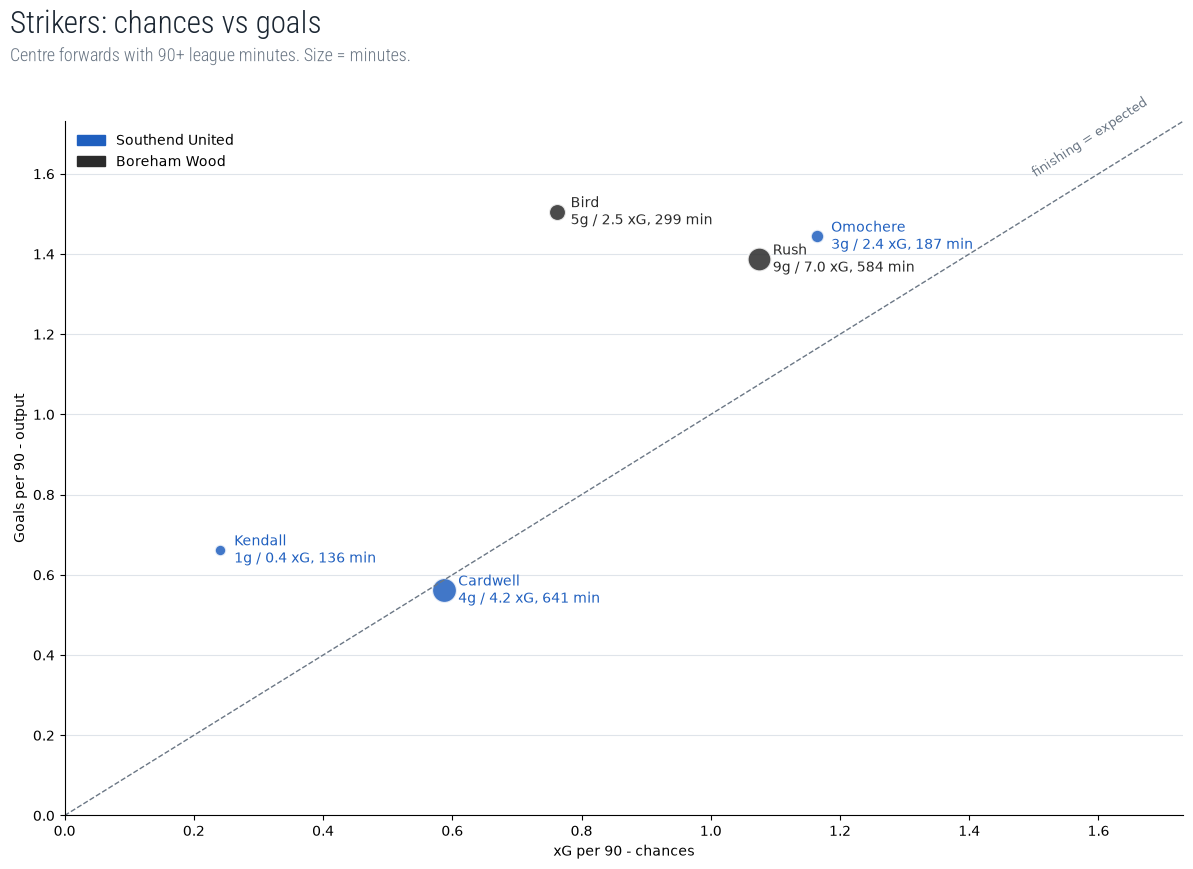

In [61]:
fig, ax = plt.subplots(figsize=(12, 8))
top = max(STRIKERS.xG_90.max(), STRIKERS.goals_90.max()) * 1.15
ax.plot([0, top], [0, top], ls="--", color=MUTED, lw=1)
ax.text(top * 0.97, top * 0.92, "finishing = expected", rotation=33, color=MUTED, ha="right", fontsize=9)
for _, s in STRIKERS.iterrows():
    ax.scatter(s.xG_90, s.goals_90, s=s.minutes / 2, color=COLOUR[s.team_id], alpha=0.85, edgecolor="white", lw=1.5)
    ax.annotate(f"{surname(s.player)}\n{s.goals}g / {s.xG:.1f} xG, {s.minutes} min", (s.xG_90, s.goals_90),
                xytext=(10, 0), textcoords="offset points", va="center", fontsize=10, color=COLOUR[s.team_id])
ax.set_xlim(0, top)
ax.set_ylim(0, top)
ax.set_xlabel("xG per 90 - chances")
ax.set_ylabel("Goals per 90 - output")
team_legend(ax, loc="upper left")
tidy(ax)
chart_title(fig, "Strikers: chances vs goals", "Centre forwards with 90+ league minutes. Size = minutes.")
plt.show()

## Striker scorecards

Four ways of measuring a striker side by side: how often they shoot, how good the chances
are, how often they hit the target and how often they score.

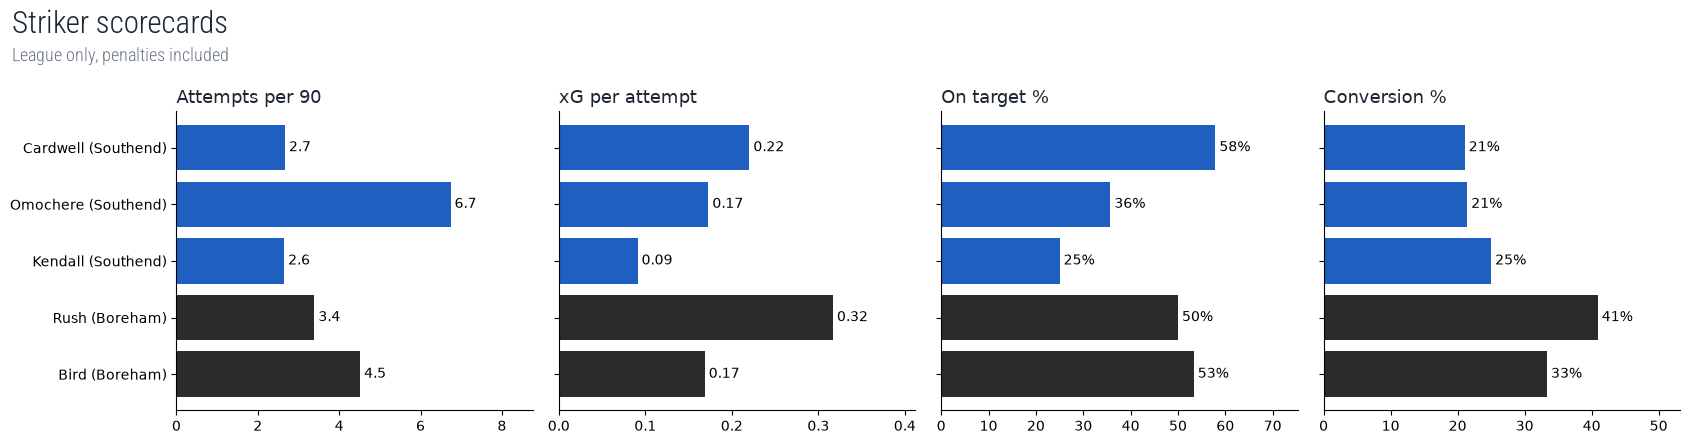

In [62]:
METRICS = [("attempts_90", "Attempts per 90", "{:.1f}"), ("xG_per_shot", "xG per attempt", "{:.2f}"),
           ("on_target_pct", "On target %", "{:.0f}%"), ("conversion", "Conversion %", "{:.0f}%")]
ordered = STRIKERS.sort_values(["team_id", "minutes"], key=lambda c: c.map({US: 0, RIVAL: 1}) if c.name == "team_id" else c,
                               ascending=[True, False])
fig, axs = plt.subplots(1, 4, figsize=(17, 1 + 0.55 * len(ordered)), sharey=True)
labels = [f"{surname(p)} ({NAME[t].split()[0]})" for p, t in zip(ordered.player, ordered.team_id)]
for ax, (col, title, fmt) in zip(axs, METRICS):
    ax.barh(labels, ordered[col], color=[COLOUR[t] for t in ordered.team_id])
    for i, v in enumerate(ordered[col]):
        ax.text(v, i, " " + fmt.format(v), va="center", fontsize=10)
    ax.set_title(title, loc="left", color=TEXT, fontsize=13)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_xlim(0, ordered[col].max() * 1.3 if ordered[col].max() else 1)
axs[0].invert_yaxis()
chart_title(fig, "Striker scorecards", "League only, penalties included")
plt.show()

## Striker shot maps

Every attempt by each team's two most-used strikers. Size = xG, red ring = goal.

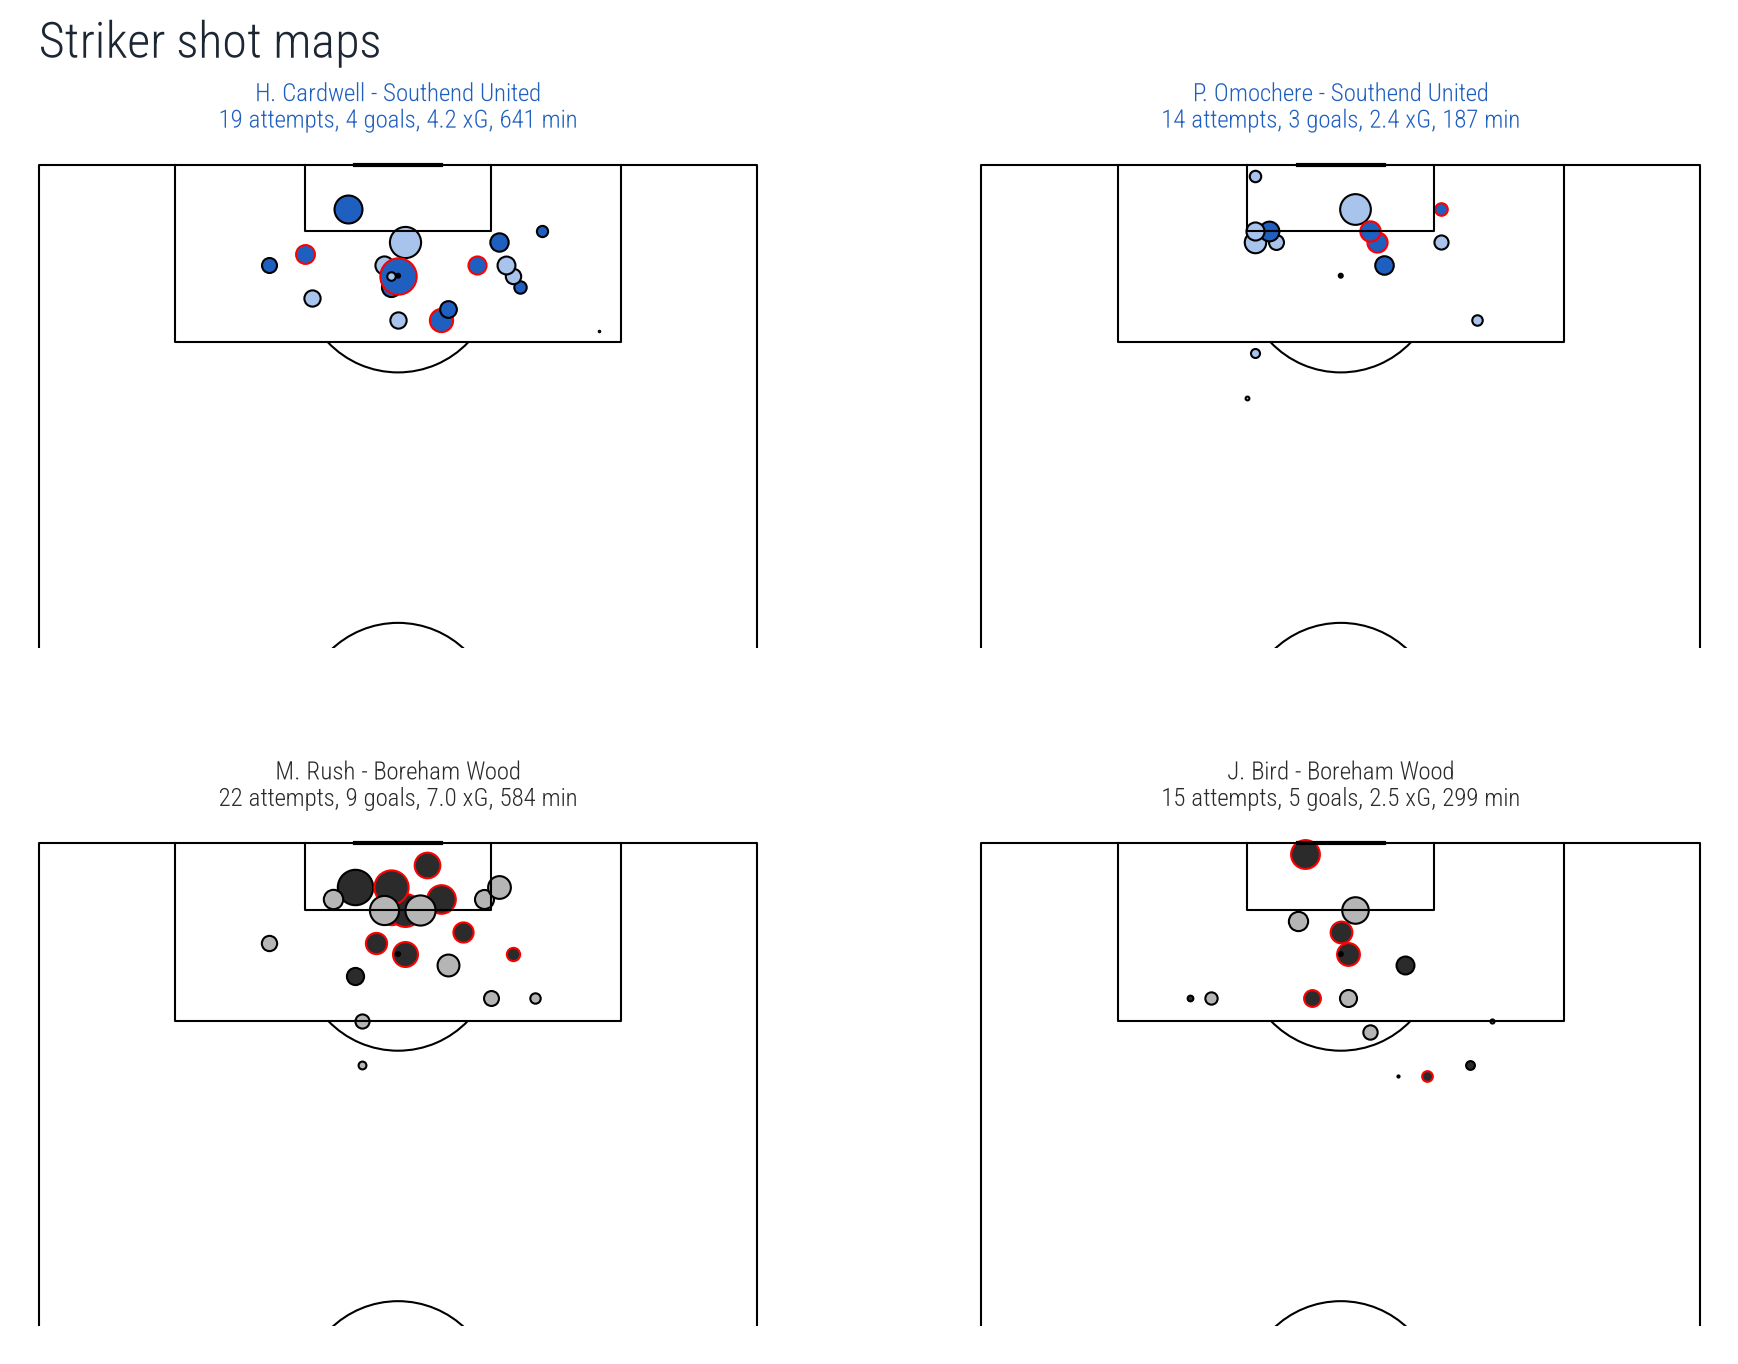

In [63]:
top_two = {t: STRIKERS[STRIKERS.team_id == t].nlargest(2, "minutes") for t in TEAMS}
cols = max(len(df) for df in top_two.values())
pitch = make_pitch(half=True, linewidth=1.5, pad_top=4, pad_bottom=-10)
fig, axs = pitch.grid(nrows=2, ncols=cols, figheight=14, title_height=0.05, title_space=0.04, endnote_height=0.01,
                      axis=False, grid_height=0.85, space=0.14)
grid = np.atleast_2d(axs["pitch"]).reshape(2, cols)
for row, t in enumerate(TEAMS):
    for col in range(cols):
        ax = grid[row, col]
        if col >= len(top_two[t]):
            ax.set_visible(False)
            continue
        s = top_two[t].iloc[col]
        plot_shots(s.shots, (COLOUR[t], LIGHT[t]), pitch, ax, base_size=900)
        ax.set_title(f"{s.player} - {NAME[t]}\n{s.attempts} attempts, {s.goals} goals, {s.xG:.1f} xG, "
                     f"{s.minutes} min", color=COLOUR[t], fontproperties=font(18))
axs["title"].text(0, 0.5, "Striker shot maps", fontsize=36, color=TEXT, fontproperties=APP_FONT.prop, va="center")
plt.show()

---
# 9. When the goals come

Goals scored (up) and conceded (down) in each 15-minute band, added time in each half on its
own. Own goals count for the team that benefited. Late goals are the hallmark of a team that
grinds out results.

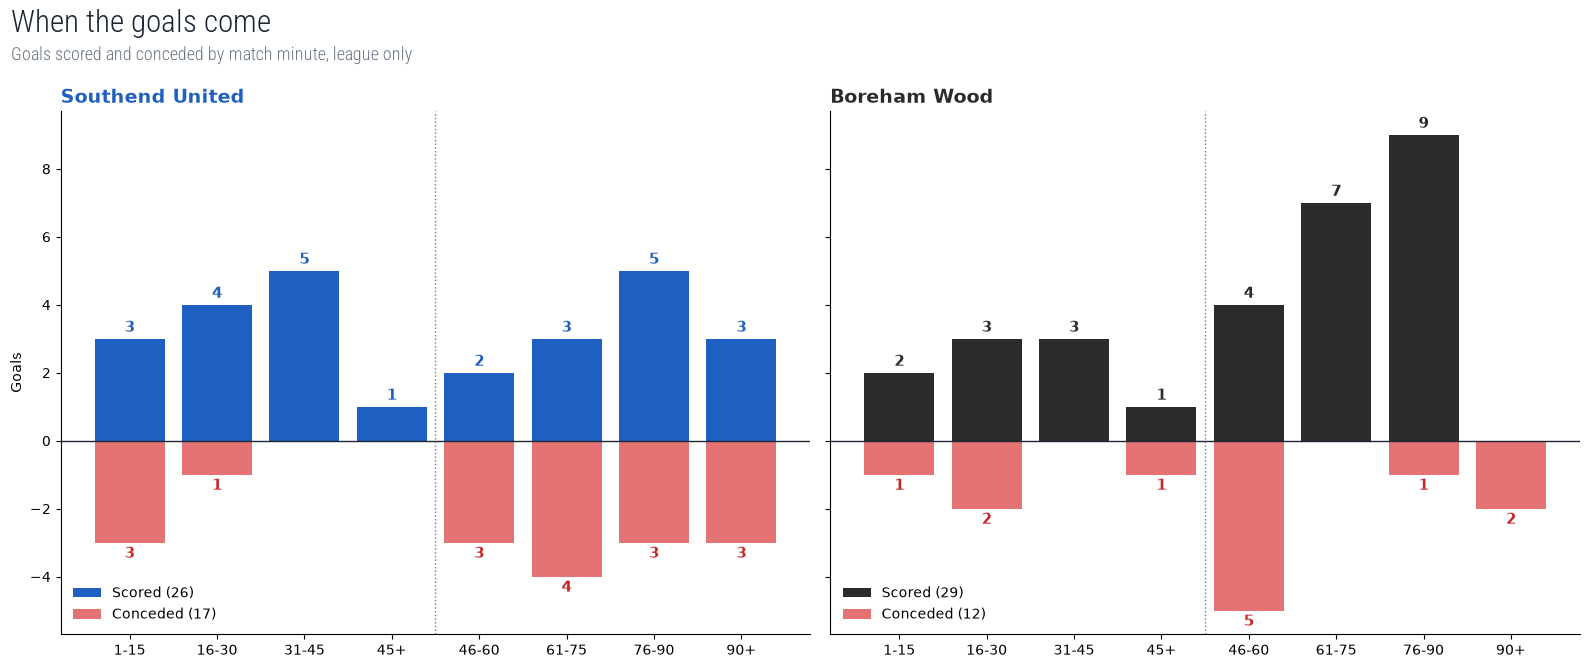

In [64]:
def goal_bands(t):
    scored, conceded = Counter(), Counter()
    for m in GAMES[t]:
        opponent = m["summary"].opponent_id
        scored.update(filters.time_band(g) for g in filters.goals_scored_by(m["events"], t))
        conceded.update(filters.time_band(g) for g in filters.goals_scored_by(m["events"], opponent))
    return scored, conceded


fig, axs = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
for ax, t in zip(axs, TEAMS):
    scored, conceded = goal_bands(t)
    xs = np.arange(len(filters.TIME_BANDS))
    up = [scored[b] for b in filters.TIME_BANDS]
    down = [-conceded[b] for b in filters.TIME_BANDS]
    ax.bar(xs, up, color=COLOUR[t], label=f"Scored ({sum(up)})")
    ax.bar(xs, down, color="#e57373", label=f"Conceded ({-sum(down)})")
    for x, u, d in zip(xs, up, down):
        if u:
            ax.text(x, u + 0.1, u, ha="center", va="bottom", fontsize=11, weight="bold", color=COLOUR[t])
        if d:
            ax.text(x, d - 0.1, -d, ha="center", va="top", fontsize=11, weight="bold", color="#c62828")
    ax.axhline(0, color=TEXT, lw=1)
    ax.axvline(3.5, color=MUTED, ls=":", lw=1)
    ax.set_xticks(xs, filters.TIME_BANDS)
    ax.set_title(NAME[t], loc="left", color=COLOUR[t], fontsize=14, weight="bold")
    ax.legend(frameon=False, loc="lower left")
    ax.spines[["top", "right"]].set_visible(False)
axs[0].set_ylabel("Goals")
chart_title(fig, "When the goals come", "Goals scored and conceded by match minute, league only")
plt.show()

---
# 10. Game state

How much of each match was spent winning, level and losing - and what the team did from
there. Points "won from losing positions" are from games where they trailed at some point;
points "dropped from winning positions" are from games they led but did not win.

Minutes are nominal (each half is 45), so added time is folded into the 45th and 90th.

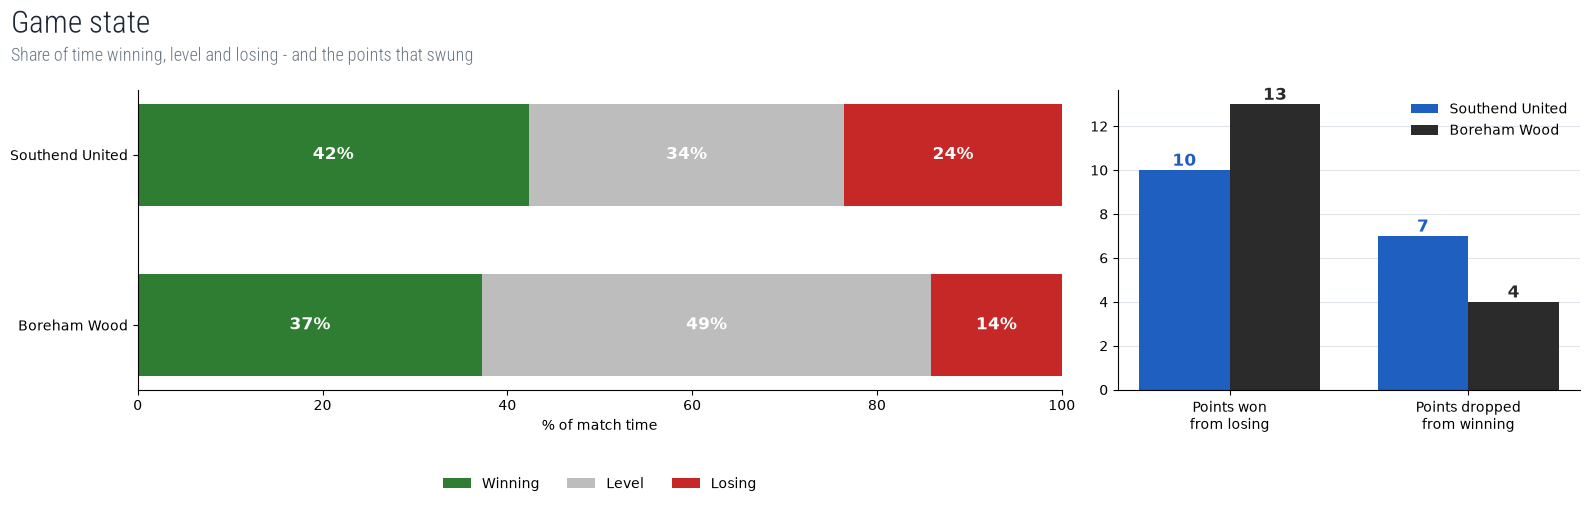

In [65]:
def game_state(m, t):
    opponent = m["summary"].opponent_id
    goals = sorted([(event_minute(g), 1) for g in filters.goals_scored_by(m["events"], t)]
                   + [(event_minute(g), -1) for g in filters.goals_scored_by(m["events"], opponent)])
    time, diff, led, trailed = 0.0, 0, False, False
    spent = Counter()
    for minute, delta in goals:
        spent["Winning" if diff > 0 else "Losing" if diff < 0 else "Level"] += minute - time
        time, diff = minute, diff + delta
        led, trailed = led or diff > 0, trailed or diff < 0
    spent["Winning" if diff > 0 else "Losing" if diff < 0 else "Level"] += 90 - time
    return spent, led, trailed


states = []
for t in TEAMS:
    for m in GAMES[t]:
        spent, led, trailed = game_state(m, t)
        points = RESULT_POINTS[m["summary"].result]
        states.append({"team_id": t, "team": NAME[t], **spent, "led": led, "trailed": trailed, "points": points,
                       "won_from_behind": points if trailed else 0, "dropped_from_ahead": 3 - points if led else 0})
states = pd.DataFrame(states).fillna(0)
summary = states.groupby("team_id")[["Winning", "Level", "Losing", "won_from_behind", "dropped_from_ahead"]].sum()
summary[["Winning", "Level", "Losing"]] = summary[["Winning", "Level", "Losing"]].div(
    summary[["Winning", "Level", "Losing"]].sum(axis=1), axis=0) * 100

fig, (left, right) = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={"width_ratios": [2, 1]})
STATE_COLOURS = {"Winning": "#2e7d32", "Level": "#bdbdbd", "Losing": "#c62828"}
for i, t in enumerate(TEAMS):
    start = 0
    for state, colour in STATE_COLOURS.items():
        share = summary.loc[t, state]
        left.barh(i, share, left=start, color=colour, height=0.6, label=state if i == 0 else None)
        if share > 6:
            left.text(start + share / 2, i, f"{share:.0f}%", ha="center", va="center", color="white", weight="bold", fontsize=12)
        start += share
left.set_yticks([0, 1], [NAME[t] for t in TEAMS])
left.invert_yaxis()
left.set_xlim(0, 100)
left.set_xlabel("% of match time")
left.legend(ncol=3, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.25))
left.spines[["top", "right"]].set_visible(False)

width = 0.38
for i, t in enumerate(TEAMS):
    vals = [summary.loc[t, "won_from_behind"], summary.loc[t, "dropped_from_ahead"]]
    xs = np.arange(2) + (i - 0.5) * width
    right.bar(xs, vals, width=width, color=COLOUR[t], label=NAME[t])
    for x, v in zip(xs, vals):
        right.text(x, v + 0.2, f"{v:.0f}", ha="center", fontsize=12, weight="bold", color=COLOUR[t])
right.set_xticks([0, 1], ["Points won\nfrom losing", "Points dropped\nfrom winning"])
right.legend(frameon=False)
tidy(right)
chart_title(fig, "Game state", "Share of time winning, level and losing - and the points that swung")
plt.show()

---
# 11. Passing style

Left: the length of every pass - a twin peak means a team that mixes short build-up with long
balls. Right: the direction of play and how much of it is long.

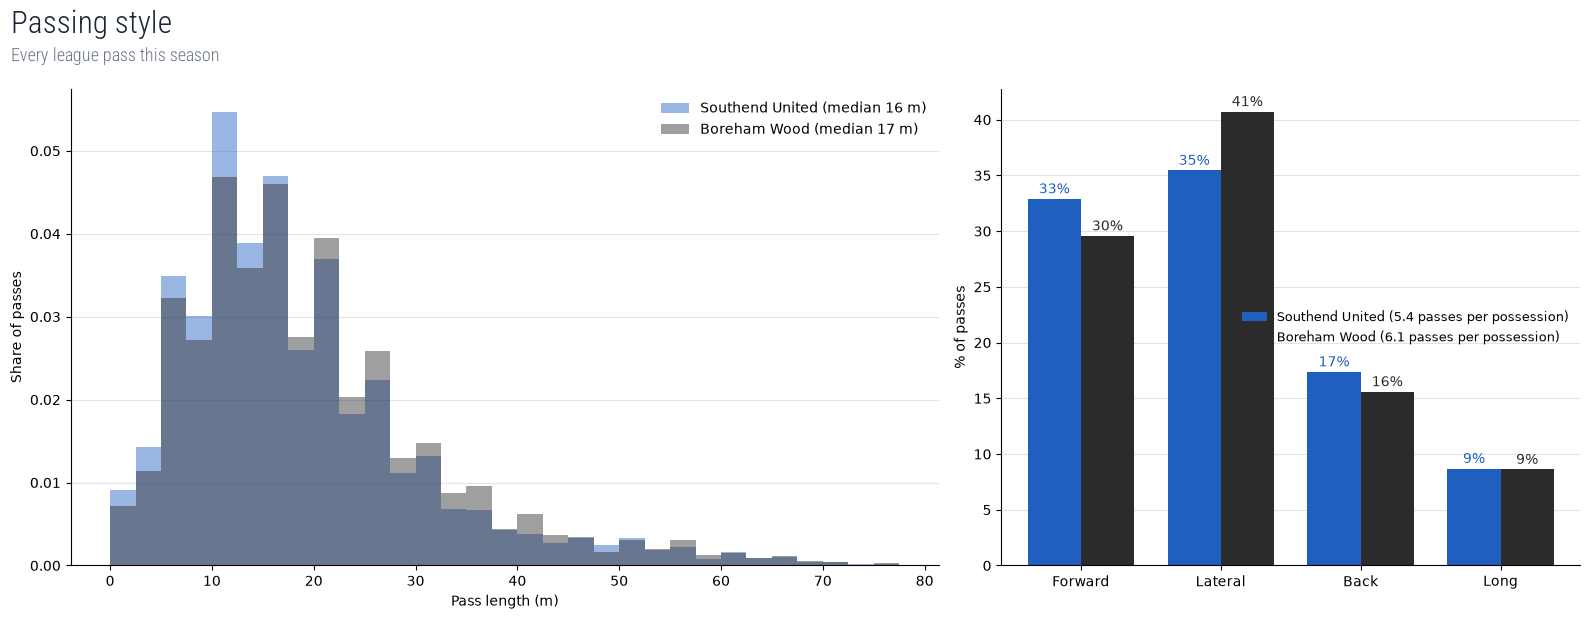

In [66]:
fig, (left, right) = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [3, 2]})
style_rows = []
for t in TEAMS:
    passes = [p for p in filters.passes(season_ours(t)) if p["pass"]["length"] is not None]
    lengths = [p["pass"]["length"] for p in passes]
    left.hist(lengths, bins=np.arange(0, 80, 2.5), density=True, histtype="stepfilled", alpha=0.45, color=COLOUR[t],
              label=f"{NAME[t]} (median {np.median(lengths):.0f} m)")
    tags = Counter(tag for p in passes for tag in filters.secondary(p))
    possessions = Counter((p.get("possession") or {}).get("id") for p in passes)
    style_rows.append({"team_id": t, "Forward": pct(tags["forward_pass"], len(passes)),
                       "Lateral": pct(tags["lateral_pass"], len(passes)), "Back": pct(tags["back_pass"], len(passes)),
                       "Long": pct(tags["long_pass"], len(passes)),
                       "passes_per_possession": np.mean(list(possessions.values()))})
left.set_xlabel("Pass length (m)")
left.set_ylabel("Share of passes")
left.legend(frameon=False)
tidy(left)

style = pd.DataFrame(style_rows).set_index("team_id")
cats = ["Forward", "Lateral", "Back", "Long"]
for i, t in enumerate(TEAMS):
    xs = np.arange(len(cats)) + (i - 0.5) * 0.38
    right.bar(xs, style.loc[t, cats], width=0.38, color=COLOUR[t],
              label=f"{NAME[t]} ({style.loc[t, 'passes_per_possession']:.1f} passes per possession)")
    for x, v in zip(xs, style.loc[t, cats]):
        right.text(x, v + 0.5, f"{v:.0f}%", ha="center", fontsize=10, color=COLOUR[t])
right.set_xticks(range(len(cats)), cats)
right.set_ylabel("% of passes")
right.legend(frameon=False, fontsize=9)
tidy(right)
chart_title(fig, "Passing style", "Every league pass this season")
plt.show()

## How the ball moves forward

Progressive passes (accurate ones that move the ball substantially towards goal) as a flow map.
The pitch is cut into a 6 x 5 grid; each arrow is the average direction of the progressive
passes that start in that zone, and the shading shows how many start there. Does each team
progress down the flanks or through the middle?

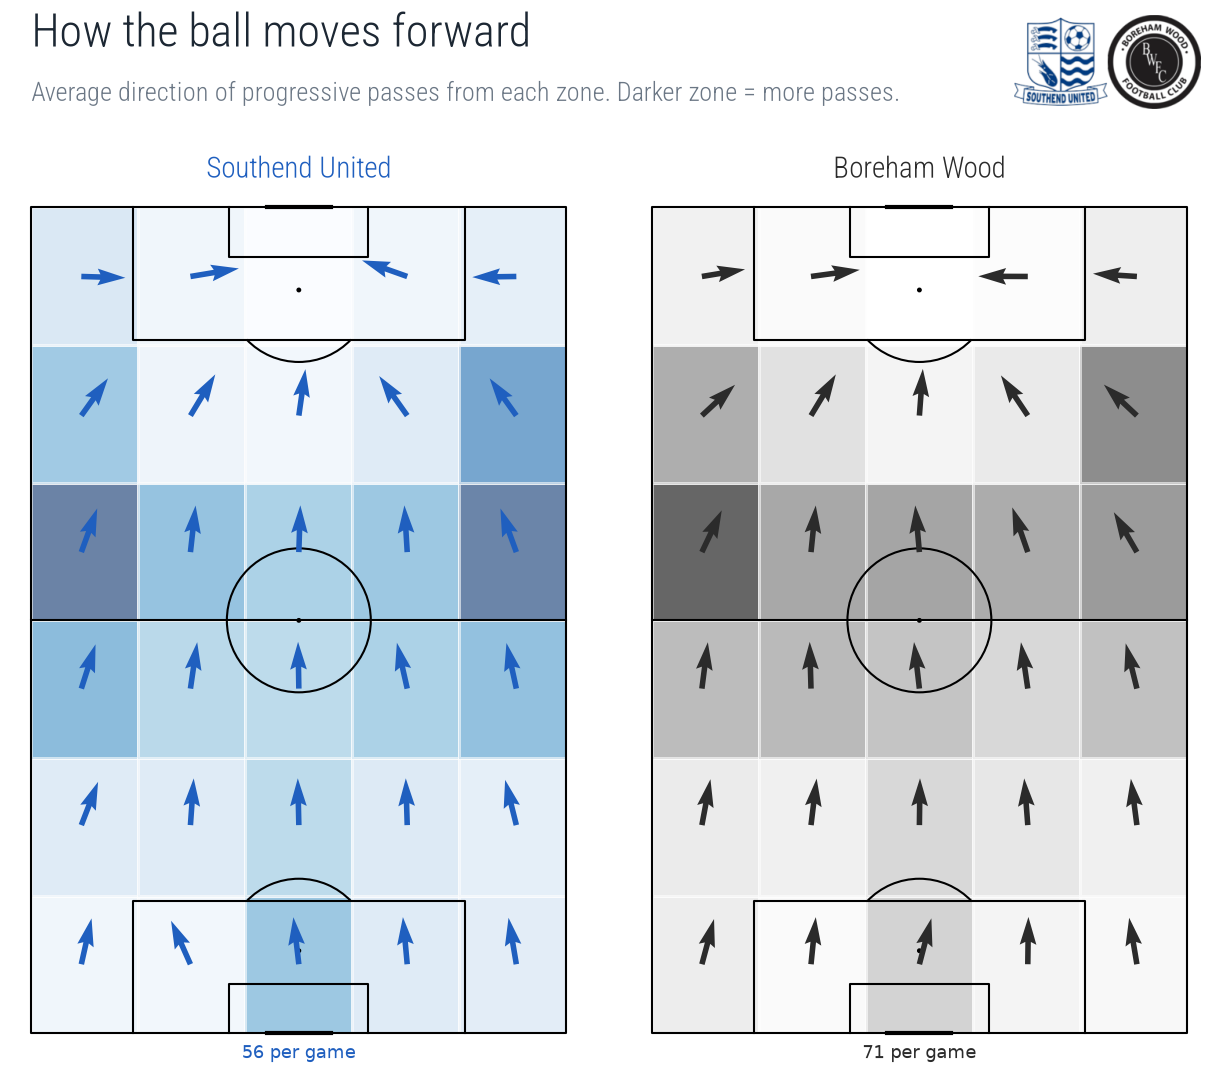

In [67]:
fig, axes, pitch = two_pitches("How the ball moves forward",
                               "Average direction of progressive passes from each zone. Darker zone = more passes.",
                               fig_height=11)
for t, ax in axes.items():
    prog = [p for p in filters.passes(season_ours(t)) if "progressive_pass" in filters.secondary(p)
            and p["pass"]["accurate"] and filters.has_location(p)]
    xs, ys = xy(prog)
    ends = np.array([filters.end_location(p) for p in prog], dtype=float).reshape(-1, 2)
    counts = pitch.bin_statistic(xs, ys, statistic="count", bins=(6, 5))
    pitch.heatmap(counts, ax=ax, cmap=CMAP[t], edgecolors="white", alpha=0.6)
    pitch.flow(xs, ys, ends[:, 0], ends[:, 1], ax=ax, bins=(6, 5), arrow_type="same", arrow_length=6,
               color=COLOUR[t], zorder=3)
    ax.text(50, -3, f"{len(prog) / len(GAMES[t]):.0f} per game", ha="center", fontsize=13, color=COLOUR[t])
plt.show()

---
# 12. Where is the gap?

Every tale-of-the-tape number, as Southend's value relative to Boreham Wood's (flipped for
the stats where lower is better). Bars to the right: Southend ahead. Bars to the left: the
areas to close.

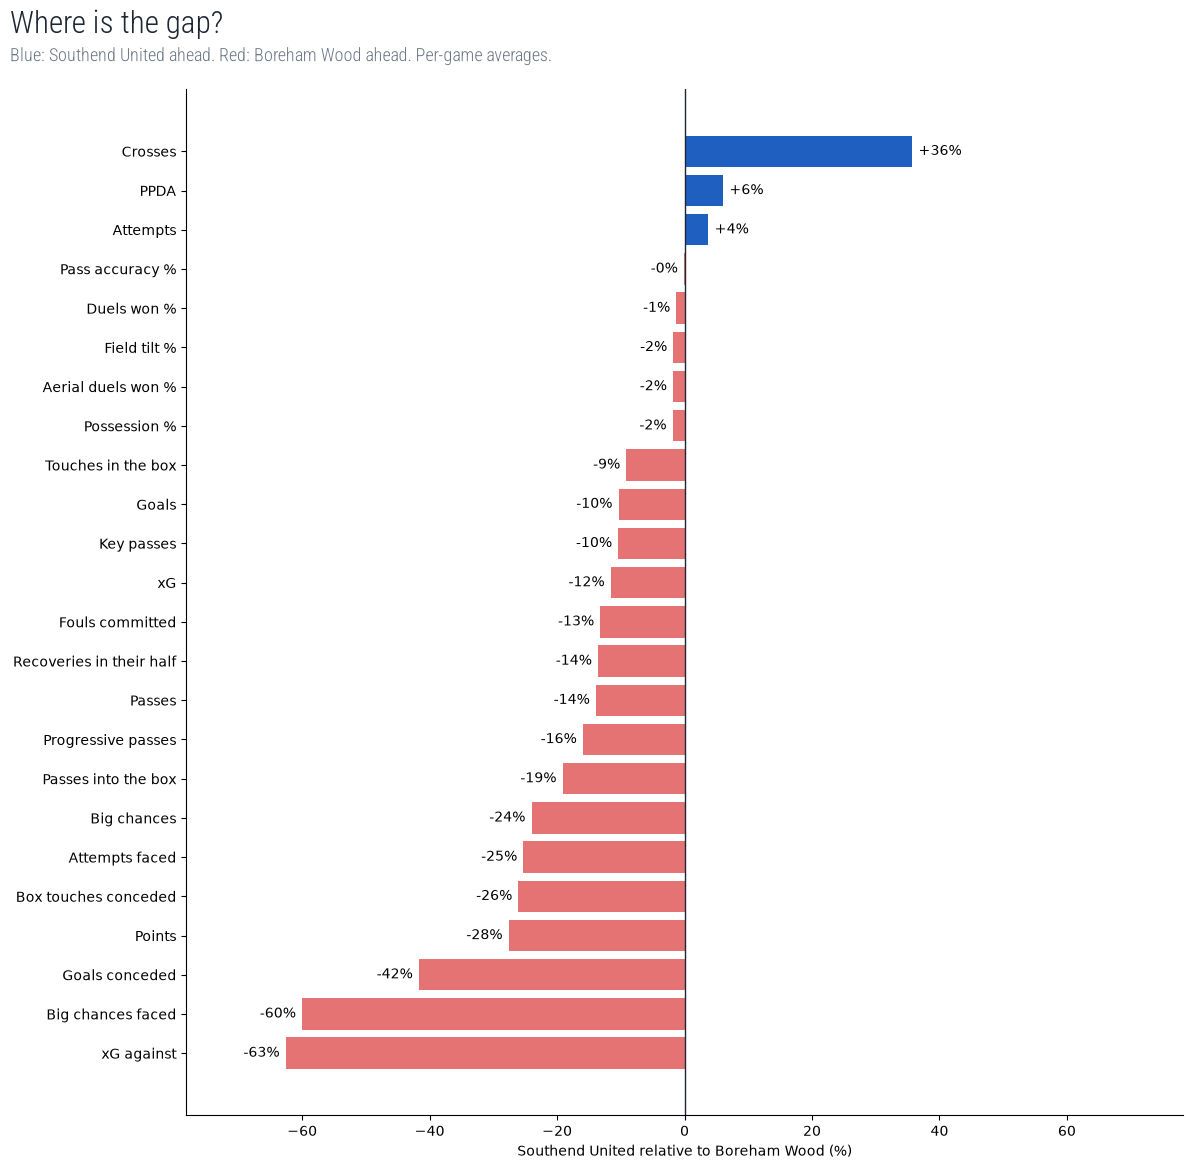

Biggest gaps to Boreham Wood:
  xG against                   1.70 vs   1.05  (-63%)
  Big chances faced            1.45 vs   0.91  (-60%)
  Goals conceded               1.55 vs   1.09  (-42%)
  Points                       1.91 vs   2.64  (-28%)
  Box touches conceded        16.27 vs  12.91  (-26%)

Where Southend United are ahead:
  Crosses                     15.55 vs  11.45  (+36%)
  PPDA                        10.05 vs  10.69  (+6%)
  Attempts                    15.18 vs  14.64  (+4%)
  Pass accuracy %             85.14 vs  85.21  (-0%)
  Duels won %                 64.79 vs  65.63  (-1%)


In [68]:
rows = []
for col, label, higher_better, _ in TAPE:
    us, them = means.loc[US, col], means.loc[RIVAL, col]
    edge = (us - them) / them * 100 if them else 0
    rows.append({"metric": label, "Southend": us, "Rival": them, "edge %": edge if higher_better else -edge})
gap = pd.DataFrame(rows).sort_values("edge %")

fig, ax = plt.subplots(figsize=(12, 11))
ax.barh(gap.metric, gap["edge %"], color=[COLOUR[US] if v >= 0 else "#e57373" for v in gap["edge %"]])
for i, v in enumerate(gap["edge %"]):
    ax.text(v + (1 if v >= 0 else -1), i, f"{v:+.0f}%", va="center", ha="left" if v >= 0 else "right", fontsize=10)
ax.axvline(0, color=TEXT, lw=1)
ax.set_xlabel(f"{NAME[US]} relative to {NAME[RIVAL]} (%)")
ax.spines[["top", "right"]].set_visible(False)
lim = gap["edge %"].abs().max() * 1.25
ax.set_xlim(-lim, lim)
chart_title(fig, "Where is the gap?", f"Blue: {NAME[US]} ahead. Red: {NAME[RIVAL]} ahead. Per-game averages.")
plt.show()

behind = gap.head(5)
ahead = gap.tail(5).iloc[::-1]
print(f"Biggest gaps to {NAME[RIVAL]}:")
for _, r in behind.iterrows():
    print(f"  {r.metric:<26} {r.Southend:6.2f} vs {r.Rival:6.2f}  ({r['edge %']:+.0f}%)")
print(f"\nWhere {NAME[US]} are ahead:")
for _, r in ahead.iterrows():
    print(f"  {r.metric:<26} {r.Southend:6.2f} vs {r.Rival:6.2f}  ({r['edge %']:+.0f}%)")